# P3 - Annotation Prosodique pour TTS Agentique

**Navigation** : [Index](../README.md) | [<< Précédent](../04-Voix/04-9-Voice-Casting.ipynb) | [Suivant >>](04-11-Generation-TTS.ipynb)

**Pipeline en cinq passes** : lecture analytique, voice casting, annotation prosodique, génération TTS et compilation audio. Ce carnet se concentre sur l’annotation des répliques avant leur synthèse vocale.

Ce notebook enrichit les repliques identifiees en P1 avec des tags expressifs FishAudio S2-Pro. FishAudio supporte 15000+ tags expressifs (joie, colere, chuchotement, soupir, etc.) qui permettent un contrôle fin de la prosodie pour chaque personnage.

## Objectifs

1. Charger les repliques (P1) et le voice casting (P2)
2. Analyser le contexte emotionnel de chaque replique
3. Assigner des tags expressifs FishAudio S2-Pro adaptes
4. Exporter les annotations : `prosodic_annotations.json` (contrat lu par P4) et `book.ssml.md` (livre de relecture)

**Duree estimee** : 8-10 minutes

***


## 1. Configuration et imports

Le notebook **P3 — Annotation prosodique** prend les **résultats combinés de P1 (analyse textuelle) et P2 (voice casting)** et produit un **livre enrichi SSML** prêt à être synthétisé par P4 (TTS). C'est la passe qui transforme un texte brut en **partition d'acteur audio** : pour chaque réplique, le moteur choisit les tags expressifs FishAudio S2-Pro qui correspondent au contexte émotionnel.

### Trois répertoires contractuels

| Répertoire | Source | Contenu |
|------------|--------|---------|
| `BASE_DIR = "output_analytique"` | P1 — Lecture analytique | `analyse_boule_de_suif.json` + `repliques.csv` + `personnages.csv` + `segments.csv` |
| `VOICE_CONFIG = "voice_casting_output/voice_casting_config.json"` | P2 — Voice casting | Configuration JSON unifiée par personnage (preset FishAudio + voix Kokoro + voix OpenAI) |
| `OUTPUT_DIR = "prosodic_output"` | P3 — produit | `book.ssml.md` (livre SSML) + `prosodic_annotations.json` (annotations structurées) |

Les trois répertoires forment un **pipeline de fichiers en chaîne** : P3 ne fait rien sans P1+P2. Si P1/P2 n'ont pas tourné, le notebook lève `FileNotFoundError` au chargement — c'est volontaire, on ne simule pas de fallback comme dans P2, parce qu'annoter un texte sans l'avoir analysé serait du remplissage.

### Imports choisis et leur rôle

- `json` / `csv` : sérialisation des données P1 et export des annotations structurées
- `re` : détection des majuscules sostenues (colère/cris, exercice) et des points de suspension multiples
- `dataclass` + `field` : modèle `ProsodicAnnotation` immutable avec `tags_applied: list = field(default_factory=list)` — pattern obligatoire pour les listes mutables par défaut
- `Path` : résolution portable des chemins (le notebook s'exécute sur Windows ET Linux grâce à `pathlib`)
- `Optional` : typage explicite des champs nullable

### Pourquoi `tuple` pour `load_p1_data()` et pas `dict`

Le retour `tuple` est intentionnel : P3 n'a besoin que de **4 objets ordonnés** (analysis, utterances, characters, segments), et le déballage positionnel `(analysis, utterances, characters, segments) = load_p1_data()` se lit clairement dans le code. Un `dict` ajouterait une indirection `p1["utterances"]` sans gain de clarté. C'est le **complément exact du pattern dict utilisé en P2** : dict quand le nombre de clés est ouvert ou quand le nom sémantique aide la lecture, tuple quand le contrat est figé et ordonné.

### Chemins affichés

La cellule affiche les chemins absolus des trois répertoires. Ils dépendent du dossier depuis lequel le notebook est exécuté : dans la version enregistrée, une copie locale du dépôt `jsboige/CoursIA`. Ce sont des informations de débogage, pas des secrets.


In [1]:
import json
import csv
import re
import os
import sys
import subprocess
from pathlib import Path
from dataclasses import dataclass, field, asdict
from typing import Optional

# Les cles (OpenRouter/FishAudio) viennent d'un fichier .env NON versionne, comme
# dans 04-8 et 04-9 : aucun secret n'est ecrit dans ce carnet.
try:
    from dotenv import load_dotenv
    for _env_path in [Path("../.env"), Path("../../.env"), Path("../../../.env")]:
        if _env_path.exists():
            load_dotenv(_env_path)
            break
except ImportError:
    pass

# --- Choix du dossier de travail : Google Drive, ou depot GitHub jsboige/CoursIA -------------
# On ne se contente pas de verifier qu'un dossier existe : on verifie que les FICHIERS dont le
# notebook a besoin y sont (sorties de P1 et P2, contrat P1, instrument v4). Le premier complet gagne.
DOSSIER_DRIVE = Path("/content/drive/MyDrive/04-Applications")   # adapte le chemin a ton Drive
DEPOT_URL = "https://github.com/jsboige/CoursIA.git"
DEPOT_SOUS_DOSSIER = "MyIA.AI.Notebooks/GenAI/Audio/04-Applications"
DEPOT_COLAB = Path("/content/CoursIA")

FICHIERS_REQUIS = [
    "output_analytique/analyse_boule_de_suif.json",   # P1 (04-8)
    "output_analytique/repliques.csv",
    "output_analytique/personnages.csv",
    "output_analytique/segments.csv",
    "output_analytique/p1_contract.json",              # manifeste de provenance P1
    "output_analytique/characters.json",               # contrat P1 (compte de reference)
    "output_analytique/utterances.csv",                # contrat P1 (compte de reference)
    "voice_casting_output/voice_casting_config.json",  # P2 (04-9)
    "v4/prosody_lab/syllable_pitch.py",                # instrument de mesure (section 10)
    "v4/prosody_lab/prosody_metrics.py",
]

EN_COLAB = "google.colab" in sys.modules or bool(os.getenv("COLAB_RELEASE_TAG"))

def manquants(dossier):
    """Liste des fichiers requis absents de `dossier` (tous si le dossier n'existe pas)."""
    return [f for f in FICHIERS_REQUIS if not (dossier / f).is_file()]

def candidat_drive():
    if not EN_COLAB:
        return None
    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
        return DOSSIER_DRIVE
    except Exception as e:      # montage refuse ou impossible
        print(f"Drive : montage impossible ({type(e).__name__}: {e})")
        return None

def candidat_depot_local():
    """Notebook lance depuis un clone du depot (dossier courant ou un de ses parents)."""
    ici = Path.cwd()
    # Depuis #23553 le carnet vit dans une sous-serie (04-Audiobook/, 04-Voix/,
    # 04-Musique/) : la racine de serie est donc un ANCETRE du cwd, pas le cwd.
    for dossier in [ici, *ici.parents]:
        if dossier.name == "04-Applications":
            return dossier
    for parent in [ici, *ici.parents]:
        if (parent / DEPOT_SOUS_DOSSIER).is_dir():
            return parent / DEPOT_SOUS_DOSSIER
    return None

def candidat_depot_colab():
    """Dans Colab, clone partiel du seul dossier 04-Applications (rapide, sans tout le depot)."""
    if not EN_COLAB:
        return None
    if not (DEPOT_COLAB / ".git").exists():
        try:
            subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                            DEPOT_URL, str(DEPOT_COLAB)], check=True, timeout=300)
            subprocess.run(["git", "-C", str(DEPOT_COLAB), "sparse-checkout", "set", DEPOT_SOUS_DOSSIER],
                           check=True, timeout=300)
        except Exception as e:  # reseau, git absent, delai depasse
            print(f"Depot GitHub : clonage impossible ({type(e).__name__})")
            return None
    return DEPOT_COLAB / DEPOT_SOUS_DOSSIER

TRAVAIL_DIR, bilan = None, []
for nom, fabrique in [("Google Drive", candidat_drive),
                      ("dossier courant ou clone local", candidat_depot_local),
                      ("depot GitHub (clone Colab)", candidat_depot_colab)]:
    dossier = fabrique()
    if dossier is None:
        bilan.append((nom, "absent", []))
        continue
    absents = manquants(dossier)
    bilan.append((nom, str(dossier), absents))
    if not absents:
        TRAVAIL_DIR = dossier
        break

print("Test des emplacements :")
for nom, dossier, absents in bilan:
    if dossier == "absent":
        etat, libelle = "absent ici", "-"
    else:
        etat = "OK" if not absents else f"{len(absents)} fichier(s) manquant(s)"
        libelle = Path(dossier).name            # jamais un chemin machine dans une sortie
    print(f"  - {nom:32} {etat:28} {libelle}")
    for f in absents:
        print(f"        manque : {f}")

if TRAVAIL_DIR is None:
    raise FileNotFoundError(
        "Aucun emplacement complet. Le depot GitHub ne versionne ni les sorties de P1/P2 "
        "ni le manifeste p1_contract.json : executer d'abord 04-8 (output_analytique/) puis "
        "04-9 (voice_casting_output/) dans ce dossier, ou copier ces fichiers dans "
        f"{DOSSIER_DRIVE}.")

# Dossier de la sous-serie, capture AVANT le chdir : c'est la que vit le carnet
# jumeau 04-11, alors que les artefacts P1/P2 sont a la racine de serie.
NOTEBOOK_DIR = Path.cwd()
os.chdir(TRAVAIL_DIR)       # le reste du notebook utilise des chemins relatifs a ce dossier
print(f"\nDossier de travail retenu : {Path(TRAVAIL_DIR).name}")

if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "librosa==0.11.0", "faster-whisper"], check=False)

BASE_DIR = Path("output_analytique")
VOICE_CONFIG = Path("voice_casting_output/voice_casting_config.json")
OUTPUT_DIR = Path("prosodic_output")
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"P1 output dir: {BASE_DIR}")
print(f"P2 voice config: {VOICE_CONFIG}")
print(f"P3 output dir: {OUTPUT_DIR}")

Test des emplacements :
  - Google Drive                     absent ici                   -
  - dossier courant ou clone local   OK                           04-Applications

Dossier de travail retenu : 04-Applications
P1 output dir: output_analytique
P2 voice config: voice_casting_output\voice_casting_config.json
P3 output dir: prosodic_output


## 2. Tags expressifs FishAudio S2-Pro

FishAudio S2-Pro supporte des tags expressifs inseres directement dans le texte entre crochets. Contrairement au SSML standard (limites a `<break>`, `<emphasis>`, `<prosody>`), les tags FishAudio sont beaucoup plus riches :

| Catégorie | Tags exemples | Usage narratif |
|-----------|---------------|----------------|
| **Emotions** | `[laugh]`, `[sob]`, `[sigh]`, `[gasp]` | Reactions spontanees |
| **Intensite vocale** | `[whisper]`, `[shout]`, `[mutter]` | Volume et projection |
| **Tonalite** | `[cold]`, `[warm]`, `[sarcastic]`, `[tender]` | Attitude du personnage |
| **Rythme** | `[pause]`, `[quick]`, `[slow]`, `[hesitate]` | Cadence de la parole |
| **Respiration** | `[inhale]`, `[exhale]`, `[choke]` | Effects physiologiques |
| **Paralinguistique** | `[yawn]`, `[cough]`, `[sniff]`, `[giggle]` | Sons non-verbaux |

La stratégie d'annotation combine analyse du texte (mots-clés, ponctuation) et contexte narratif (rôle du personnage, type de segment).

In [2]:
# FishAudio S2-Pro expressive tag taxonomy
# Organized by category for programmatic annotation

FISHAUDIO_TAGS = {
    "emotions": {
        "laugh": ["rire", "sourire", "sourit", "riant", "gaiete"],
        "sob": ["pleure", "pleurant", "larmes", "sanglot"],
        "sigh": ["soupir", "soupira", "soupirant"],
        "gasp": ["stupefait", "choque", "horripile", "effraye", "hoquet"],
        "groan": ["gemissement", "gemit", "grogne"],
    },
    "intensity": {
        "whisper": ["murmura", "murmure", "chuchota", "chuchotement", "voix basse", "a voix basse"],
        "shout": ["cria", "crier", "hurlement", "vocifera", "hurla"],
        "mutter": ["marmonna", "grommela", "bougonna", "entre ses dents"],
    },
    "tone": {
        "cold": ["froidement", "froid", "glacial", "sans emotion", "indifference"],
        "warm": ["chaleureux", "tendrement", "avec douceur", "affectueux"],
        "sarcastic": ["sarcastique", "ironique", "ironiquement", "derision"],
        "tender": ["tendresse", "tendrement", "avec tendresse", "doux"],
        "indignant": ["indignation", "indigne", "furieux", "colere", "courroux"],
        "timid": ["timidement", "timide", "hesitant", "craintivement"],
        "onctuous": ["onction", "onctueusement", "sousveillance", "diplomatie", "avec un sourire"],
    },
    "rhythm": {
        "pause": ["...", " - ", "silence", "un moment"],
        "hesitate": ["euh", "bah", "enfin", "comment dire"],
        "quick": ["precipitamment", "vite", "hative", "preSSIPit"],
    },
    "breath": {
        "inhale": ["inspira", "aspiration", "reprenant son souffle"],
        "exhale": ["expira", "souffla", "relachement"],
        "choke": ["etouffa", "etrangla", "voix tremblante"],
    },
}

print(f"Taxonomie FishAudio : {sum(len(v) for v in FISHAUDIO_TAGS.values())} tags en {len(FISHAUDIO_TAGS)} categories")
for cat, tags in FISHAUDIO_TAGS.items():
    print(f"  {cat}: {', '.join(tags.keys())}")

Taxonomie FishAudio : 21 tags en 5 categories
  emotions: laugh, sob, sigh, gasp, groan
  intensity: whisper, shout, mutter
  tone: cold, warm, sarcastic, tender, indignant, timid, onctuous
  rhythm: pause, hesitate, quick
  breath: inhale, exhale, choke


## 3. Chargement des données P1 et P2

Cette étape **consomme les artefacts des deux passes précédentes** (P1 analyse textuelle + P2 voice casting) pour reconstituer le **graphe narratif annoté**.

### Mesures de cette exécution

P1 et P2 ont été régénérés en exécutant les carnets 04-8 et 04-9 du dépôt. Les dossiers `output_analytique/` et `voice_casting_output/` ne sont pas versionnés ; c'est le **manifeste `p1_contract.json`** (version 1.0, produit par 04-8) qui atteste la provenance du corpus chargé, et non la présence d'un fichier au bon nom.

| Donnée | Source | Valeur mesurée |
|--------|--------|----------------|
| Segments P1 | `segments.csv` | **342** segments : 302 de narration, 39 de dialogue, 1 de description |
| Répliques P1 | `repliques.csv` | **39** répliques |
| Personnages P1 | `personnages.csv` | **9** personnages |
| Contrat P1 | `p1_contract.json` | version 1.0, source *Boule de Suif* (Gutenberg #10746, texte 83 097 caractères) |
| Personnages P2 | `voice_casting_config.json` | **9** personnages castés (cohérent avec P1) |

La cellule ci-dessous confronte les deux côtés : le nombre de lignes **chargées** et le nombre **annoncé** par le manifeste. Un écart lève avec les deux nombres et le remède exact, au lieu de laisser un corpus étranger passer en silence — l'incident d'origine était un lot de 14 segments d'une génération antérieure consommé sans avertissement.

**Ce qui a changé depuis la version précédente de ce notebook.** Les sorties enregistrées auparavant décrivaient un extrait de démonstration (14 segments, 9 répliques, 8 personnages) **sans accents**, dont les répliques contenaient leur incise (« murmura Boule de Suif »). Le P1 actuel analyse le conte entier **avec ses accents**, et sépare la réplique de la phrase narrative qui l'introduit (« Boule de Suif répondit sèchement : » est un segment narratif distinct). Ces deux changements expliquent une partie des résultats de la suite :
- la taxonomie, écrite sans accents, rate des mots accentués ;
- les verbes de parole ne sont plus dans le texte des répliques.

L'exemple guidé de la section 4 traite ces deux points.

**Attribution des répliques.** 21 des 39 répliques sont attribuées au Narrateur, c'est-à-dire que P1 n'a pas identifié le personnage qui parle, et d'autres sont attribuées au mauvais personnage. Une émotion bien détectée peut donc être portée par la mauvaise voix. La section 6 bis corrige en P3 ce que la phrase d'introduction de chaque réplique permet de corriger, signale les répliques non résolues et liste les corrections à reporter en P1.

### Pourquoi `csv.DictReader` et pas `pandas.read_csv`

P3 manipule des **données structurées simples** (des fichiers CSV plats). `pandas.DataFrame` serait overkill pour des dizaines de lignes — overhead mémoire et dépendance dure. `csv.DictReader` retourne des `OrderedDict` directement utilisables comme `utterance["speaker"]` / `utterance["text"]`. C'est aussi plus **lisible pour un étudiant** qui voit la structure de données sans abstraction supplémentaire.

### Pourquoi `tuple` de retour, pas `dict`

Le retour `(analysis, utterances, characters, segments)` est positionnel et stable : `analysis` (json brut), puis les 3 CSV. L'appelant déballe en 4 variables, et Python sait à la compilation que c'est un `tuple[dict, list[dict], list[dict], list[dict]]`. Un `dict` aurait ajouté 4 niveaux d'indirection (`p1["segments"]`) pour 0 gain de clarté. Pattern inverse à P2 où `dict` était préféré pour sa flexibilité — voir cell[1] ci-dessus pour la justification détaillée.

In [3]:
# Contrat P1 canonique v1.0 -- MEME organe que 04-9 (manifeste p1_contract.json).
# Le manifeste est la reference de provenance : il nomme le producteur, la
# version et les comptes attendus. Sans lui, rien n'atteste la generation des
# fichiers charges -- des artefacts d'une generation anterieure ont deja ete
# consommes ici en silence (14 segments au lieu des 342 annonces).
P1_CONTRACT = BASE_DIR / "p1_contract.json"


def load_p1_contract() -> dict:
    if not P1_CONTRACT.exists():
        raise RuntimeError(
            f"[CONTRAT P1] {P1_CONTRACT} introuvable : executer "
            f"04-8-Lecture-Analytique.ipynb dans ce dossier avant 04-10."
        )
    contract = json.loads(P1_CONTRACT.read_text(encoding="utf-8"))
    source = contract.get("source", {})
    print(f"[CONTRAT P1 v{contract.get('version', '?')}] produit par "
          f"{contract.get('producer', '?')} | source : {source.get('title', '?')} "
          f"(Gutenberg #{source.get('gutenberg_id', '?')}, "
          f"texte {source.get('text_length', '?')} car.)")
    return contract


def load_p1_data() -> tuple:
    # Charger P1 selon le contrat canonique v1 (aucun artefact de provenance inconnue).
    contract = load_p1_contract()
    # Load P1 analysis results
    with open(BASE_DIR / "analyse_boule_de_suif.json", encoding="utf-8") as f:
        analysis = json.load(f)

    # Load utterances (repliques)
    utterances = []
    with open(BASE_DIR / "repliques.csv", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            utterances.append(row)

    # Load character info
    characters = []
    with open(BASE_DIR / "personnages.csv", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            characters.append(row)

    # Load segments
    segments = []
    with open(BASE_DIR / "segments.csv", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            segments.append(row)

    # Provenance : le manifeste decrit les fichiers du CONTRAT ; 04-10 charge
    # les fichiers LEGACY. On mesure les deux cotes et on exige l'accord, sinon
    # un corpus etranger passe en silence -- c'est ce qui s'est produit (sorties
    # committees : 14 segments, 9 repliques, 8 personnages, contre 342 / 39 / 9).
    def _count_rows(name: str) -> int:
        with open(BASE_DIR / name, encoding="utf-8") as fh:
            return sum(1 for _ in csv.DictReader(fh))

    chars_path = BASE_DIR / "characters.json"
    if not chars_path.exists():
        raise RuntimeError(
            f"[CONTRAT P1] {chars_path} introuvable : executer "
            f"04-8-Lecture-Analytique.ipynb dans ce dossier avant 04-10."
        )
    contract_chars = json.loads(chars_path.read_text(encoding="utf-8"))
    expected = contract.get("files", {})
    # (fichier du contrat, fichier legacy charge par ce carnet, legacy, contrat)
    pairs = [
        ("characters.json", "personnages.csv", len(characters), len(contract_chars)),
        ("segments.csv", "segments.csv", len(segments), expected.get("segments.csv")),
        ("utterances.csv", "repliques.csv", len(utterances), _count_rows("utterances.csv")),
    ]
    problems = []
    for contract_file, legacy_file, legacy_n, contract_n in pairs:
        announced = expected.get(contract_file)
        if announced != contract_n:
            problems.append(
                f"{contract_file} porte {contract_n} entree(s) sur disque "
                f"contre {announced if announced is not None else '?'} annonce(s)"
            )
        if legacy_n != contract_n:
            problems.append(
                f"{legacy_file} (charge par ce carnet) porte {legacy_n} entree(s) "
                f"contre {contract_file} = {contract_n}"
            )
    if problems:
        raise RuntimeError(
            "[CONTRAT P1] Corpus incoherent dans "
            f"{BASE_DIR} : {' ; '.join(problems)}. "
            "Re-executer 04-8-Lecture-Analytique.ipynb dans ce dossier."
        )
    for contract_file, legacy_file, legacy_n, contract_n in pairs:
        print(f"{contract_file:16s} {contract_n:4d} entree(s) "
              f"(manifeste : {expected.get(contract_file):4d}) | "
              f"{legacy_file:16s} {legacy_n:4d} chargee(s)")

    return analysis, utterances, characters, segments


def load_p2_config() -> dict:
    # Load P2 voice casting configuration
    with open(VOICE_CONFIG, encoding="utf-8") as f:
        return json.load(f)


analysis, utterances, characters, segments = load_p1_data()
voice_config = load_p2_config()

print(f"P1 - Segments: {len(segments)}, Repliques: {len(utterances)}, Personnages: {len(characters)}")
print(f"P2 - Personnages castes: {len(voice_config['characters'])}")
print(f"\nPremieres repliques:")
for u in utterances[:5]:
    print(f"  [{u['speaker']}] {u['text'][:70]}...")

[CONTRAT P1 v1.0] produit par 04-8-Lecture-Analytique.ipynb | source : Boule de Suif (Gutenberg #10746, texte 83097 car.)


characters.json     9 entree(s) (manifeste :    9) | personnages.csv     9 chargee(s)
segments.csv      342 entree(s) (manifeste :  342) | segments.csv      342 chargee(s)
utterances.csv     39 entree(s) (manifeste :   39) | repliques.csv      39 chargee(s)
P1 - Segments: 342, Repliques: 39, Personnages: 9
P2 - Personnages castes: 9

Premieres repliques:
  [Narrateur] J'emmène ma
femme,...
  [Narrateur] J'en fais autant.«--«Et moi aussi....
  [Narrateur] Nous ne reviendrons pas à Rouen, et si les Prussiens
approchent du Hav...
  [Narrateur] Pourquoi ne montez-vous
pas dans la voiture, vous serez à l'abri, au m...
  [Narrateur] Tout le
monde est-il monté?...


## 4. Moteur d'annotation prosodique

Le moteur d'annotation fonctionne en trois étapes pour chaque replique :

1. **Analyse lexicale** : Detection de mots-clés emotionnels dans le texte et les didascalies
2. **Contexte narratif** : Rôle du personnage, type de segment (dialogue/narration), position dans l'intrigue
3. **Sélection des tags** : Choix des tags FishAudio les plus adapttes, avec positionnement dans le texte

Les tags sont inseres aux endroits stratégiques du texte (debut de phrase, pauses naturelies, changements emotionnels).

> **Statut de ce moteur.** Les sections 4 à 6 présentent le **moteur d'origine (v1)**. Il est conservé comme référence de comparaison, mais ce n'est **pas lui qui est exporté**. Le moteur exporté est le **moteur retenu (v2)**, défini à la section 6 bis à partir des corrections validées par les exercices. Deux corrections sont toutefois appliquées dès cette section, parce qu'elles ne changent pas les règles de détection : l'ordre des tags est stable, et la correspondance entre noms de personnages et identifiants s'appuie sur les identifiants communs à P1 et P2 au lieu d'une table codée en dur.


In [4]:
@dataclass
class ProsodicAnnotation:
    # A single utterance with prosodic annotation (moteur d'origine v1, conservé pour comparaison)
    seg_index: int
    speaker: str
    original_text: str
    annotated_text: str
    tags_applied: list = field(default_factory=list)
    emotion_profile: str = ""
    fish_preset: str = ""
    utterance_type: str = "dialogue"


# Ordre de référence des tags : celui de la taxonomie (émotions, intensité, ton, rythme, souffle)
ORDRE_TAXONOMIE = [tag for categorie in FISHAUDIO_TAGS.values() for tag in categorie]


def detect_emotion_tags(text: str) -> list:
    # Detect FishAudio tags from text content and stage directions
    text_lower = text.lower()
    detected = []

    for category, tag_dict in FISHAUDIO_TAGS.items():
        for tag_name, keywords in tag_dict.items():
            for kw in keywords:
                if kw in text_lower:
                    detected.append(tag_name)
                    break  # One match per tag is enough

    # Punctuation-based tags
    if "!" in text and text.count("!") >= 2:
        detected.append("shout")
    # Single exclamation: intensity handled by context, no extra tag needed
    # Question mark: default intonation, no extra tag needed
    if "..." in text:
        if "pause" not in detected:
            detected.append("pause")

    # Ordre STABLE : la version initiale renvoyait list(set(detected)), dont l'ordre varie d'un
    # processus Python à l'autre (hachage aléatoire des chaînes), alors que le premier tag est
    # celui placé en tête du texte. Les règles de détection, elles, sont inchangées.
    rang = {tag: i for i, tag in enumerate(ORDRE_TAXONOMIE)}
    return sorted(set(detected), key=lambda tag: rang.get(tag, len(rang)))


# --- Correspondance des personnages : identifiants COMMUNS à P1 et P2 ---------------------
# La version initiale utilisait une table codée en dur, qui contenait "elisabeth_rousset"
# (absent de P1 et de P2, dont l'identifiant est "boule_de_suif") et ignorait "Mme Loiseau" :
# ces deux personnages recevaient en silence la voix du narrateur. On part désormais des
# identifiants de personnages.csv (P1), vérifiés contre voice_casting_config.json (P2).
import unicodedata as _ud
from collections import Counter

def _cle_nom(nom):
    nom = "".join(c for c in _ud.normalize("NFD", nom) if _ud.category(c) != "Mn")
    return " ".join(nom.lower().replace("-", " ").split())

NARRATEUR_ID = "narrateur"
PRESET_NARRATEUR_DEFAUT = "narrator_male"   # même valeur par défaut que annotate_segment et que P4
ID_PAR_NOM = {_cle_nom(c["full_name"]): c["id"] for c in characters}
IDS_P1 = {c["id"] for c in characters}
IDS_P2 = set(voice_config["characters"])
PRESET_NARRATEUR = (voice_config["characters"].get(NARRATEUR_ID, {}).get("voices", {})
                    .get("fishaudio_production", {}).get("preset", PRESET_NARRATEUR_DEFAUT))


def get_speaker_profile(speaker: str, characters: list, voice_config: dict) -> dict:
    """Profil vocal d'un locuteur à partir des identifiants communs P1/P2.
    resolution : "p1" (nom reconnu dans P1), "narrateur" (P1 n'a pas identifié qui parle),
                 "inconnu" (nom absent de P1 : signalé, jamais converti en narrateur sans le dire)."""
    cle = _cle_nom(speaker)
    if cle == NARRATEUR_ID:
        char_id, resolution = NARRATEUR_ID, "narrateur"
    elif cle in ID_PAR_NOM:
        char_id, resolution = ID_PAR_NOM[cle], "p1"
    else:
        char_id, resolution = None, "inconnu"

    if char_id == NARRATEUR_ID:
        role = "narrateur"
    else:
        role = next((c["role"] for c in characters if c["id"] == char_id), "figurant")

    if char_id in voice_config.get("characters", {}):
        fish_preset = voice_config["characters"][char_id]["voices"]["fishaudio_production"]["preset"]
    elif char_id == NARRATEUR_ID:
        fish_preset = PRESET_NARRATEUR
    else:
        fish_preset = "neutral"

    return {"char_id": char_id, "role": role, "fish_preset": fish_preset, "resolution": resolution}


print("Moteur d'annotation prosodique defini.")
print(f"Taxonomie : {sum(len(v) for v in FISHAUDIO_TAGS.values())} cles emotionnelles")
print(f"\nIdentifiants P1 = P2 : {IDS_P1 == IDS_P2} ({len(IDS_P1)} personnages)"
      + ("" if IDS_P1 == IDS_P2 else f" | P1 seul : {sorted(IDS_P1 - IDS_P2)} | P2 seul : {sorted(IDS_P2 - IDS_P1)}"))
print(f"Narrateur : {'présent' if NARRATEUR_ID in IDS_P2 else 'absent'} de P2 -> preset {PRESET_NARRATEUR!r}"
      + ("" if NARRATEUR_ID in IDS_P2 else " (valeur par défaut, la même que P4)"))
print("\nLocuteurs des répliques P1 :")
for nom, n in Counter(u["speaker"] for u in utterances).most_common():
    p = get_speaker_profile(nom, characters, voice_config)
    print(f"  {nom:26} x{n:2d} -> {str(p['char_id']):14} ({p['resolution']}, preset {p['fish_preset']})")


Moteur d'annotation prosodique defini.
Taxonomie : 21 cles emotionnelles

Identifiants P1 = P2 : True (9 personnages)
Narrateur : absent de P2 -> preset 'narrator_male' (valeur par défaut, la même que P4)

Locuteurs des répliques P1 :
  Narrateur                  x21 -> narrateur      (narrateur, preset narrator_male)
  Monsieur Loiseau           x 6 -> loiseau        (p1, preset expressive_male_neutral)
  Comte Hubert de Breville   x 5 -> comte          (p1, preset expressive_male_neutral)
  Mme Loiseau                x 2 -> mme_loiseau    (p1, preset expressive_female_neutral)
  Officier prussien          x 2 -> officier       (p1, preset expressive_male_cold)
  Les bonnes soeurs          x 1 -> soeurs         (p1, preset neutral_female)
  Elisabeth Rousset          x 1 -> boule_de_suif  (p1, preset expressive_female_warm)
  Cornudet                   x 1 -> cornudet       (p1, preset expressive_male_neutral)


### Exemple guidé : détecteur d'émotion par ponctuation (groupe G17, PR #23242)

**Duree estimee :** 10-15 minutes

**Objectif** : Etendre la fonction `detect_emotion_tags` pour detecter des emotions supplementaires a partir de la ponctuation et des majuscules. Actuellement, seule la repetition de "!" est detectee. Ajoutez la detection des majuscules sostenues (colere/cris) et des points de suspension multiples (hesitation/suspense).

**Contexte** : Le texte de Maupassant utilise peu de didascalies explicites, mais la ponctuation encode beaucoup d'information emotionnelle. Les majuscules sostenues signalent l'indignation, les points de suspension l'hesitation ou le sous-entendu.

- **Étape 1 :** Detecter les suites de majuscules (> 3 lettres majuscules consecutives = cris)
- **Étape 2 :** Detecter les points de suspension multiples ("..." = hesitation, "...." = longue pause)
- **Étape 3 :** Integrer dans detect_emotion_tags et tester sur les repliques existantes

**Indice :** re.search(r'[A-Z]{3,}', text) detecte les suites de majuscules
**Indice :** text.count('...') > 1 indique des hesitations repetees

In [5]:
    # Exemple guidé — résolution du groupe G17 (Killian Barret), PR #23242, revue et intégrée.
# Exercice : détecteur d'émotion par ponctuation (et marquage robuste au français réel)
import re
import unicodedata
from collections import Counter

# --- Normalisation commune ---------------------------------------------------------
# La taxonomie est écrite SANS accents ("colere", "stupefait", "indigne") alors que le texte
# P1 actuel est accentué ("colère", "stupéfait", "indignée") : une comparaison directe rate ces
# mots. On compare donc les deux sous une forme commune : minuscules, sans diacritiques,
# apostrophe typographique unifiée, retours à la ligne remplacés par des espaces.
# Cette forme garde la longueur du texte (une lettre accentuée précomposée reste une lettre),
# ce qui permet de reporter une position trouvée dans le texte normalisé sur le texte d'origine.
def normaliser_fr(texte):
    texte = texte.replace("’", "'").replace("\n", " ").replace("\t", " ")
    texte = unicodedata.normalize("NFC", texte)
    texte = "".join(unicodedata.normalize("NFD", c)[0] for c in texte)
    return texte.lower()

# --- Étape 1 : majuscules soutenues -------------------------------------------------
ACRONYMES = {"NASA", "SNCF", "URSS", "OTAN"}  # sigles : des capitales qui ne sont pas des cris

def detect_caps_shouting(text):
    """Vrai si le texte contient un mot de plus de 3 lettres entièrement en capitales.
    - Lettres Unicode : « ÉCOUTEZ » compte en entier (la regex [A-Z] n'en voit que « COUTEZ »).
    - Les sigles connus ne sont pas des cris.
    - Un titre (« BOULE DE SUIF ») n'a ni minuscule ni ponctuation expressive : ce n'est pas un cri."""
    mots = [m for m in re.findall(r"[^\W\d_]+", text)
            if len(m) > 3 and m.isupper() and m not in ACRONYMES]
    if not mots:
        return False
    est_titre = not any(c.islower() for c in text) and not re.search(r"[!?]", text)
    return not est_titre

# --- Étape 2 : points de suspension -----------------------------------------------
# « ... » (trois points) et « … » (caractère unique U+2026, courant en typographie française)
# sont la même marque. Quatre points ou plus, ou « …… », signalent une longue pause.
RE_SUSPENSION = re.compile(r"\.{3,}|…+")

def compter_suspensions(text):
    """Renvoie (nombre de marques de suspension, nombre de longues pauses)."""
    marques = RE_SUSPENSION.findall(text)
    longues = [m for m in marques if m.count(".") >= 4 or m.count("…") >= 2]
    return len(marques), len(longues)

def detect_hesitation(text):
    """Hésitation = points de suspension répétés (au moins deux marques dans la réplique).
    Une marque isolée reste un simple [pause] (sous-entendu, suspense)."""
    return compter_suspensions(text)[0] >= 2

# --- Étape 3 : version étendue -------------------------------------------------------
# Ordre stable : celui de la taxonomie (émotions, intensité, ton, rythme, souffle).
# La version d'origine renvoie list(set(...)) : l'ordre, donc le tag placé en tête du texte
# annoté, change d'une exécution Python à l'autre (hachage aléatoire des chaînes).
ORDRE_TAGS = [tag for categorie in FISHAUDIO_TAGS.values() for tag in categorie]

def _compiler_mot_cle(mot_cle):
    """Mot-clé ancré en début de mot : « froid » trouve « froidement » mais plus « refroidie »,
    « rire » ne trouve plus « prirent », « vite » ne trouve plus « éviter ».
    Les mots-clés de pure ponctuation (« ... », « - ») sont traités par les règles de ponctuation."""
    forme = normaliser_fr(mot_cle).strip()
    if not re.search(r"\w", forme):
        return None
    return re.compile(r"(?<!\w)" + re.escape(forme))

# L'ancrage fait perdre « intimidée » (« timide » n'est plus trouvé au milieu du mot) :
# on ajoute la racine correspondante, plutôt que de revenir à la recherche de sous-chaîne.
MOTS_CLES_AJOUTES = {"timid": ["intimid"]}
MOTIFS_TAGS = {tag: [p for p in map(_compiler_mot_cle, mots_cles + MOTS_CLES_AJOUTES.get(tag, [])) if p]
               for categorie in FISHAUDIO_TAGS.values() for tag, mots_cles in categorie.items()}

def tags_lexicaux(texte):
    forme = normaliser_fr(texte)
    return {tag for tag, motifs in MOTIFS_TAGS.items() if any(p.search(forme) for p in motifs)}

def detect_emotion_tags_v2(text, contexte=""):
    """Version étendue de detect_emotion_tags.
    1. Mots-clés sur texte normalisé (accents) et ancrés en début de mot (faux positifs).
    2. Ponctuation : majuscules soutenues ou au moins deux « ! » -> shout ;
       suspensions répétées -> hesitate ; toute suspension (dont « … » et « .... ») -> pause.
    3. contexte (facultatif) : l'incise narrative qui introduit la réplique
       (« Boule de Suif répondit sèchement : »). Seuls ses mots-clés comptent, pas sa ponctuation.
    4. Ordre déterministe (ordre de la taxonomie)."""
    trouves = tags_lexicaux(text) | (tags_lexicaux(contexte) if contexte else set())
    if detect_caps_shouting(text) or text.count("!") >= 2:
        trouves.add("shout")
    if detect_hesitation(text):
        trouves.add("hesitate")
    if compter_suspensions(text)[0]:
        trouves.add("pause")
    return [tag for tag in ORDRE_TAGS if tag in trouves]

# Phrase d'introduction : dans le P1 actuel, « dit-il », « répondit-elle sèchement »… ne sont
# plus dans la réplique mais à la fin du segment narratif qui la précède (terminé par « : »).
# On ne garde que la dernière proposition : après le dernier « . ! ? ; » et après la dernière
# citation fermée (« … »), pour ne pas attribuer à la réplique les mots d'une autre phrase.
segments_par_index = {int(s["index"]): s for s in segments}

def incise_precedente(seg_index):
    """Phrase qui introduit la réplique (fin du segment narratif précédent, terminé par « : »)."""
    precedent = segments_par_index.get(seg_index - 1)
    if not precedent or precedent["seg_type"] == "dialogue":
        return ""
    texte = " ".join(precedent["text"].split()).rstrip("-— ").strip()
    if not texte.endswith(":"):
        return ""
    texte = re.split(r"[.!?;»]\s*", texte[:-1])[-1]
    return texte.lstrip("-— ").strip() + ":"

# --- Tests unitaires : la ponctuation expressive est rare dans ce conte, on vérifie donc
# chaque règle sur des cas construits, avec la réponse attendue écrite à l'avance.
indice_regex = lambda t: bool(re.search(r"[A-Z]{3,}", t))   # l'indice de l'énoncé, pour comparaison
cas_majuscules = [
    ("JAMAIS ! Vous ne m'aurez pas !", True),
    ("Hé ! ÉCOUTEZ-MOI bien.", True),
    ("BOULE DE SUIF", False),                # titre
    ("Il travaillait pour la NASA.", False),  # sigle
    ("Il dit NON !", False),                  # 3 lettres : sous le seuil « plus de 3 lettres »
    ("Mon Dieu ! murmura Boule de Suif.", False),
]
cas_suspensions = [
    ("Il attendit...", (1, 0), False),
    ("Il attendit…", (1, 0), False),
    ("Je... je ne sais pas... enfin.", (2, 0), True),
    ("Et puis.... plus rien.", (1, 1), False),
    ("Euh… c'est-à-dire…… non.", (2, 1), True),
]
print(f"{'texte':38} {'attendu':>8} {'v2':>6} {'indice [A-Z]{3,}':>17}")
for texte, attendu in cas_majuscules:
    obtenu = detect_caps_shouting(texte)
    assert obtenu == attendu, texte
    print(f"{texte:38} {attendu!s:>8} {obtenu!s:>6} {indice_regex(texte)!s:>17}")
print()
for texte, compte, hesite in cas_suspensions:
    assert compter_suspensions(texte) == compte and detect_hesitation(texte) == hesite, texte
    print(f"{texte:38} marques/longues={compte} hésitation={hesite!s:5} "
          f"| v1 voit « ... » : {'...' in texte!s:5} | v2 : {detect_emotion_tags_v2(texte)}")
print("Tous les tests unitaires passent.\n")

# --- Application aux répliques du P1 ----------------------------------------------
print("Ponctuation dans les répliques : majuscules soutenues =",
      sum(detect_caps_shouting(u["text"]) for u in utterances),
      "| suspensions =", sum(compter_suspensions(u["text"])[0] for u in utterances),
      "| répliques avec au moins deux « ! » =", sum(u["text"].count("!") >= 2 for u in utterances))

comparaison_ex1 = []
for u in utterances:
    idx = int(u["seg_index"])
    v1 = sorted(detect_emotion_tags(u["text"]))
    v2 = detect_emotion_tags_v2(u["text"])
    incise = incise_precedente(idx)
    v2c = detect_emotion_tags_v2(u["text"], incise)
    comparaison_ex1.append(dict(seg=idx, speaker=u["speaker"], v1=v1, v2=v2, v2_contexte=v2c, incise=incise))

print(f"\n{'seg':>4} {'personnage':22} {'v1':18} {'v2':18} {'v2 + intro':22} phrase d'introduction")
for c in comparaison_ex1:
    if c["v1"] or c["v2"] or c["v2_contexte"]:
        print(f"{c['seg']:4d} {c['speaker'][:22]:22} {','.join(c['v1']) or '-':18} "
              f"{','.join(c['v2']) or '-':18} {','.join(c['v2_contexte']) or '-':22} {c['incise'][-75:]}")
print(f"\nRépliques taguées : v1 {sum(bool(c['v1']) for c in comparaison_ex1)} / {len(comparaison_ex1)}"
      f" | v2 {sum(bool(c['v2']) for c in comparaison_ex1)}"
      f" | v2 + introduction {sum(bool(c['v2_contexte']) for c in comparaison_ex1)}"
      f" | phrases d'introduction trouvées : {sum(bool(c['incise']) for c in comparaison_ex1)}")

# --- Effet de la normalisation sur tout le conte (342 segments) ----------------------
v1_total, v2_total = Counter(), Counter()
for s in segments:
    v1_total.update(detect_emotion_tags(s["text"]))
    v2_total.update(detect_emotion_tags_v2(s["text"]))
print("\nDétections sur les 342 segments (v1 d'origine -> v2, mêmes règles de ponctuation) :")
for tag in ORDRE_TAGS:
    if v1_total[tag] or v2_total[tag]:
        print(f"  {tag:10} {v1_total[tag]:3d} -> {v2_total[tag]:3d}")


texte                                   attendu     v2  indice [A-Z]{3,}
JAMAIS ! Vous ne m'aurez pas !             True   True              True
Hé ! ÉCOUTEZ-MOI bien.                     True   True              True
BOULE DE SUIF                             False  False              True
Il travaillait pour la NASA.              False  False              True
Il dit NON !                              False  False              True
Mon Dieu ! murmura Boule de Suif.         False  False             False

Il attendit...                         marques/longues=(1, 0) hésitation=False | v1 voit « ... » : True  | v2 : ['pause']
Il attendit…                           marques/longues=(1, 0) hésitation=False | v1 voit « ... » : False | v2 : ['pause']
Je... je ne sais pas... enfin.         marques/longues=(2, 0) hésitation=True  | v1 voit « ... » : True  | v2 : ['pause', 'hesitate']
Et puis.... plus rien.                 marques/longues=(1, 1) hésitation=False | v1 voit « ... » : True  | v2 


 seg personnage             v1                 v2                 v2 + intro             phrase d'introduction
  39 Narrateur              -                  -                  hesitate                lieu de quatre à cause du tirage plus pénible, une voix du dehors demanda:
  97 Narrateur              -                  -                  timid                  osse fille intimidée, et, prenant son grand air de gentilhomme, il lui dit:
 141 Narrateur              shout              shout              shout                  Elle balbutiait:
 166 Narrateur              -                  -                  whisper                it la dure carcasse de sa compagne qu'il réveilla d'un baiser en murmurant:
 170 Narrateur              pause,shout,sob    sob,shout,pause    sob,shout,pause        Le vieux rat d'église lui répondit:
 212 Narrateur              -                  -                  shout                  Il lui cria:
 238 Monsieur Loiseau       pause,shout        shout,pause  


Détections sur les 342 segments (v1 d'origine -> v2, mêmes règles de ponctuation) :


  laugh       17 ->  12
  sob          4 ->   5
  sigh         4 ->   4
  gasp         0 ->   3
  whisper      8 ->   9
  shout       15 ->  15
  mutter       1 ->   1
  cold         8 ->   6
  tender       3 ->   3
  indignant    5 ->  12
  timid        2 ->   4
  onctuous     3 ->   1
  pause       13 ->  13
  hesitate    14 ->  15
  quick        7 ->   6
  inhale       1 ->   1
  exhale       3 ->   3
  choke        0 ->   2


### Analyse de l'exemple guidé : marquage par la ponctuation

**Ce que la ponctuation apporte sur ce texte.** Dans les 39 répliques du conte, la ponctuation expressive est rare :
- **aucun mot en majuscules** : le seul mot en capitales du conte est le titre « BOULE DE SUIF », que la règle écarte ;
- **deux marques de suspension**, une dans chacune de deux répliques, donc aucune hésitation répétée ;
- **trois répliques** avec au moins deux « ! ».

Les règles des étapes 1 et 2 sont donc vérifiées sur des cas construits (tests unitaires), avec la réponse attendue écrite à l'avance. Chez Maupassant, l'émotion passe surtout par les mots et par les verbes qui introduisent les répliques, peu par la typographie.

**Trois choix techniques, justifiés par le français.**
- *Majuscules.* L'énoncé dit « plus de 3 lettres », mais l'indice propose `[A-Z]{3,}`, soit 3 lettres ou plus. La solution suit l'énoncé et travaille sur les lettres Unicode : `[A-Z]` ignore les capitales accentuées (dans « ÉCOUTEZ », il ne voit que « COUTEZ ») et ne trouve donc le mot que par chance. Elle écarte aussi les sigles et les titres, que l'indice signale à tort comme des cris (« NASA », « BOULE DE SUIF »).
- *Points de suspension.* Le français typographié utilise souvent le caractère unique « … » (U+2026), que le test `"..." in text` d'origine ne voit pas. Les deux formes sont reconnues : une marque isolée donne `pause`, deux marques ou plus donnent `hesitate`, et quatre points ou plus signalent une longue pause.
- *Accents et frontières de mots.* Le tableau final de la sortie compare la version d'origine à la v2 sur les 342 segments, avec les mêmes règles de ponctuation. La taxonomie est écrite sans accents, alors que le texte P1 actuel est accentué : en normalisant, `indignant` passe de 5 à 12 détections (« colère », « indignée »), et `gasp` (« stupéfait », « effrayé ») et `choke` (« étouffa », « étrangla ») apparaissent, alors qu'ils n'étaient jamais détectés. L'ancrage en début de mot supprime des faux positifs : « prirent », « inscrire » et « souffrirent » pour `laugh` (mot-clé « rire »), « fonction » pour `onctuous` (« onction »), « refroidie » pour `cold` (« froid »), « éviter » et « gravité » pour `quick` (« vite »). L'ancrage faisait aussi perdre un vrai cas, « intimidée » pour `timid`, rattrapé en ajoutant la racine « intimid ».

**Le levier principal : la phrase qui introduit la réplique.** Dans le P1 actuel, le verbe qui qualifie la réplique (« répondit sèchement », « en murmurant », « cria ») n'est plus dans la réplique, mais à la fin du segment narratif qui la précède, terminé par « : ». La lire fait passer les répliques taguées de **4 à 13 sur 39**. Les **10** répliques que la phrase d'introduction touche (9 qui passent de non-taguées à taguées, plus le seg 335 qui s'enrichit) ont été relues une à une :

| Verdict | Segments | Exemple |
|---|---|---|
| Juste (6) | 166, 212, 278, 286, 317, 335 | « en murmurant » → `whisper` ; « Il lui cria » → `shout` ; « avec indignation » → `indignant` |
| Approximatif (1) | 248 | « le comte souffla un léger : Chut ! » → `exhale`. La taxonomie associe « souffla » au souffle, alors que l'intention est un chuchotement |
| Faux (3) | 39, 295, 97 | « Enfin, … » au sens temporel → `hesitate` (39, 295) ; « la grosse fille intimidée » décrit l'interlocutrice, pas le comte qui parle → `timid` (97) |

**Ce que cette phrase révèle aussi : des erreurs d'attribution.** Elle nomme souvent la personne qui parle, et ce nom contredit parfois P1 :
- « Mme Loiseau eut un rire muet de triomphe et murmura : » précède une réplique attribuée à Monsieur Loiseau (seg 335) ;
- c'est aussi le cas de « le tempérament populacier de Mme Loiseau éclata : » (seg 238) ;
- « Loiseau, qui titubait, … lui dit en bredouillant : » précède une réplique attribuée à Cornudet (seg 295).

Un tag juste porté par la mauvaise voix reste une erreur à l'écoute. La section 6 bis applique ces corrections en P3 et les liste pour qu'elles soient reportées en P1, où elles doivent finalement être faites.

**Reproductibilité.** La fonction d'origine renvoie `list(set(...))`. L'ordre des tags, donc le tag placé en tête du texte annoté, change d'une exécution Python à l'autre. C'est vérifié en faisant varier `PYTHONHASHSEED` : pour la réplique de Cornudet de l'ancien extrait, le tag de tête est tantôt `laugh`, tantôt `onctuous`. La v2 trie les tags dans l'ordre de la taxonomie, et la fonction d'origine a été corrigée de la même façon (section 4).

**Limites.** Les mots-clés restent des indices, pas une compréhension du texte :
- « enfin » déclenche `hesitate` alors qu'il s'agit le plus souvent d'un adverbe de temps ;
- un mot d'émotion peut décrire une autre personne que celle qui parle (« Elle pleure sa honte » donne `sob`) ;
- une négation (« sans colère ») trompe la règle.

Ces corrections sont intégrées au **moteur retenu** (section 6 bis), qui est celui exporté. Il va plus loin sur deux limites relevées ici : « enfin » n'y déclenche plus `hesitate`, et un son non verbal cité dans les paroles (« Elle pleure sa honte ») n'y est pas exécuté.


### Exercice : interjections et onomatopées

**Durée estimée :** 10-15 minutes

**Objectif** : construire `detecter_interjections(texte)`, qui associe les **interjections** du texte à un tag de `FISHAUDIO_TAGS` (catégorie `breath` ou `emotions`), à partir d'un lexique explicite.

**Contexte** : l'exemple guidé traite la ponctuation (majuscules, suspensions). Les interjections sont l'autre versant du même problème : « hélas », « hein », « eh bien » portent une émotion que la ponctuation seule ne donne pas. Le piège est symétrique : une interjection en fin de phrase n'est pas un cri, et un mot ordinaire ne doit pas être confondu avec une interjection.

- **Étape 1 :** écrire le dictionnaire `INTERJECTIONS` (interjection → tag de la taxonomie)
- **Étape 2 :** normaliser le texte sans accents et **ancrer** chaque interjection en début de mot, comme `_compiler_mot_cle` le fait déjà
- **Étape 3 :** appliquer aux 39 répliques, puis compter combien de répliques la fonction enrichit par rapport à `detect_emotion_tags_v2`

**Indice :** commence par trois entrées seulement (« hélas » → `sigh`, « hein » → `hesitate`, « eh bien » → `pause`) et vérifie chaque ajout sur une réplique réelle.
**Indice :** une interjection de plusieurs mots (« eh bien ») doit être cherchée avant sa forme courte, sinon « eh » la masque.

In [6]:
# Exercice a completer : interjections et onomatopees -> tags de la taxonomie
INTERJECTIONS = {
    # TODO etudiant : interjection -> tag de FISHAUDIO_TAGS (ex. "helas": "sigh", "hein": "hesitate")
}

def detecter_interjections(texte):
    """Tags portes par les interjections du texte (sans accents, ancrage en debut de mot)."""
    # TODO etudiant
    return []  # TODO etudiant

# Etape 3 : appliquer aux repliques et comparer a detect_emotion_tags_v2
# TODO etudiant : compter les repliques que la fonction enrichit

print("Exercice a completer")

Exercice a completer


In [7]:
def annotate_utterance(utterance: dict, characters: list, voice_config: dict) -> ProsodicAnnotation:
    # Annotate a single utterance with FishAudio expressive tags
    text = utterance["text"]
    speaker = utterance["speaker"]
    seg_index = int(utterance.get("seg_index", utterance.get("index", 0)))
    utterance_type = utterance.get("utterance_type", "dialogue")

    # Get speaker profile
    profile = get_speaker_profile(speaker, characters, voice_config)

    # Step 1: Detect emotion tags from text
    tags = detect_emotion_tags(text)

    # Step 2: Add contextual tags based on role and segment type
    if profile["role"] == "narrateur":
        if "cold" not in tags and "warm" not in tags:
            pass  # Narrator uses default neutral tone
    elif profile["role"] == "antagoniste":
        if "cold" not in tags and "sarcastic" not in tags:
            tags.append("cold")  # Antagonists default to cold tone
    elif profile["role"] == "protagoniste":
        if not any(t in tags for t in ["warm", "indignant", "sob", "gasp"]):
            tags.append("warm")  # Protagonist default warmth

    # Step 3: Build annotated text with tags inserted at natural positions
    annotated = text
    tag_placements = []

    # Prepend primary emotion tag
    if tags:
        primary_tag = tags[0]
        annotated = f"[{primary_tag}] {annotated}"
        tag_placements.append(("start", primary_tag))

    # Insert pause tags at sentence boundaries
    if ". " in text and len(tags) > 1:
        parts = annotated.split(". ", 1)
        if len(parts) == 2:
            secondary = tags[1] if len(tags) > 1 else "pause"
            annotated = f"{parts[0]}. [{secondary}] {parts[1]}"
            tag_placements.append(("mid", secondary))

    # Determine emotion profile string
    emotion_profile = "+".join(tags[:3]) if tags else "neutral"

    return ProsodicAnnotation(
        seg_index=seg_index,
        speaker=speaker,
        original_text=text,
        annotated_text=annotated,
        tags_applied=tags,
        emotion_profile=emotion_profile,
        fish_preset=profile["fish_preset"],
        utterance_type=utterance_type,
    )


print("Fonction d'annotation definie.")

Fonction d'annotation definie.


## 5. Pipeline d'annotation (moteur d'origine v1, pour comparaison)

Application du moteur d'origine à toutes les répliques P1. Ces annotations servent de **référence de comparaison** pour les exercices et pour la section 6 bis ; elles ne sont pas exportées.


In [8]:
# Run full prosodic annotation pipeline
annotations = []

for u in utterances:
    ann = annotate_utterance(u, characters, voice_config)
    annotations.append(ann)

print(f"{len(annotations)} repliques annotees")
print("\n--- Apercu des annotations ---")
for ann in annotations:
    tags_str = ", ".join(ann.tags_applied) if ann.tags_applied else "(neutral)"
    print(f"\n[{ann.speaker}] (seg {ann.seg_index}) preset={ann.fish_preset}")
    print(f"  Tags: {tags_str}")
    print(f"  Profil: {ann.emotion_profile}")
    print(f"  Texte annote: {ann.annotated_text[:90]}...")

39 repliques annotees

--- Apercu des annotations ---

[Narrateur] (seg 25) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: J'emmène ma
femme,...

[Narrateur] (seg 27) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: J'en fais autant.«--«Et moi aussi....

[Narrateur] (seg 29) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: Nous ne reviendrons pas à Rouen, et si les Prussiens
approchent du Havre nous gagnerons l'...

[Narrateur] (seg 35) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: Pourquoi ne montez-vous
pas dans la voiture, vous serez à l'abri, au moins....

[Narrateur] (seg 39) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: Tout le
monde est-il monté?...

[Narrateur] (seg 41) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: Oui....

[Narrateur] (seg 50) preset=narrator_male
  Tags: (neutral)
  Profil: neutral
  Texte annote: Il est im

## 6. Annotation des segments narratifs (moteur d'origine v1, pour comparaison)

Les segments de narration et de description reçoivent également des tags prosodiques pour guider le narrateur (rythme, pauses, intensité). Comme à la section 5, ces annotations v1 servent de référence de comparaison et ne sont pas exportées.


In [9]:
def annotate_segment(seg: dict) -> dict:
    # Annotate a narration/description segment for narrator
    text = seg["text"]
    seg_type = seg["seg_type"]
    tags = []

    # Detect emotional content
    text_lower = text.lower()
    if any(w in text_lower for w in ["peur", "effroi", "angoisse", "horreur"]):
        tags.append("pause")
        tags.append("slow")
    if any(w in text_lower for w in ["precipit", "vite", "soudain", "brusquement"]):
        tags.append("quick")
    if any(w in text_lower for w in ["silence", "calme", "tranquil", "paisibl"]):
        tags.append("slow")
        tags.append("pause")
    if any(w in text_lower for w in ["neige", "froid", "glac", "hiver"]):
        tags.append("cold")
    if "..." in text:
        tags.append("pause")

    # Default for narration
    if not tags:
        if seg_type == "description":
            tags = ["slow"]
        else:
            tags = ["pause"]

    # Build annotated text
    primary = tags[0]
    annotated = f"[{primary}] {text}"

    return {
        "seg_index": int(seg["index"]),
        "seg_type": seg_type,
        "original_text": text,
        "annotated_text": annotated,
        "tags_applied": tags,
        "speaker": "Narrateur",
        "fish_preset": "narrator_male",
    }


# Get dialogue segment indices (already annotated as utterances)
dialogue_seg_indices = set()
for u in utterances:
    idx = int(u.get("seg_index", u.get("index", -1)))
    dialogue_seg_indices.add(idx)

# Annotate non-dialogue segments
segment_annotations = []
for seg in segments:
    seg_idx = int(seg["index"])
    if seg_idx not in dialogue_seg_indices:
        seg_ann = annotate_segment(seg)
        segment_annotations.append(seg_ann)

print(f"{len(segment_annotations)} segments narratifs/descriptifs annnotes")
for sa in segment_annotations:
    print(f"  [seg {sa['seg_index']}] ({sa['seg_type']}) tags: {', '.join(sa['tags_applied'])}")

303 segments narratifs/descriptifs annnotes
  [seg 0] (narration) tags: pause
  [seg 1] (narration) tags: slow, pause
  [seg 2] (narration) tags: pause
  [seg 3] (narration) tags: pause
  [seg 4] (narration) tags: pause
  [seg 5] (narration) tags: pause
  [seg 6] (narration) tags: pause
  [seg 7] (narration) tags: slow, pause
  [seg 8] (narration) tags: slow, pause
  [seg 9] (narration) tags: pause, slow
  [seg 10] (narration) tags: pause
  [seg 11] (narration) tags: pause
  [seg 12] (narration) tags: pause
  [seg 13] (narration) tags: slow, pause
  [seg 14] (narration) tags: pause
  [seg 15] (narration) tags: pause
  [seg 16] (narration) tags: pause
  [seg 17] (narration) tags: pause
  [seg 18] (narration) tags: pause
  [seg 19] (narration) tags: pause, slow
  [seg 20] (narration) tags: pause
  [seg 21] (narration) tags: quick
  [seg 22] (narration) tags: cold
  [seg 23] (narration) tags: pause
  [seg 24] (narration) tags: cold
  [seg 26] (narration) tags: pause
  [seg 28] (narration)

### Exemple guidé : enrichir les annotations des segments narratifs (groupe G17, PR #23242)

**Duree estimee :** 15 minutes

**Objectif** : Ameliorer la fonction `annotate_segment` pour detecter les changements de rythme narratif. Un passage qui accelere (mots comme "soudain", "brusquement", "precipitamment") doit recevoir le tag `[quick]`, tandis qu'un passage qui ralentit ("lentement", "doucement", "calme") doit recevoir `[slow]` en plus des tags existants.

**Contexte** : La version actuelle detecte quelques mots-clés mais manque des indicateurs de changement de rythme. En ajoutant ces detections, le narrateur TTS peut moduler sa vitesse de parole pour suivre la tension dramatique.

- **Étape 1 :** Ajouter des listes de mots-clés pour acceleration et deceleration
- **Étape 2 :** Modifier annotate_segment pour combiner les tags de rythme avec les tags existants
- **Étape 3 :** Re-annoter les segments narratifs et comparer les résultats

**Indice :** Ajoutez des mots comme "brusquement", "soudain", "vivement" pour [quick]
**Indice :** Ajoutez "lentement", "doucement", "paisiblement", "calme" pour [slow]

In [10]:
    # Exemple guidé — résolution du groupe G17 (Killian Barret), PR #23242, revue et intégrée.
# Exercice : enrichir les annotations des segments narratifs (changements de rythme)
# Étape 1 : mots-clés choisis d'après leur fréquence réelle dans le conte (formes sans accents).
# « mot* » = début de mot (toutes les terminaisons) ; « mot » sans étoile = mot entier.
QUICK_KEYWORDS = ["soudain*", "brusquement", "precipit*", "vivement", "subitement",
                  "rapidement", "vite", "tout a coup", "tout d'un coup"]
SLOW_KEYWORDS = ["lentement", "doucement", "paisibl*", "calme*", "tranquill*",
                 "peu a peu", "longuement", "interminable*", "somnol*"]
# Écartés après vérification sur le texte : « aussitôt » (enchaînement, pas débit de parole),
# « longtemps » (durée de l'action), « immobile » (posture), « éclata » (souvent un rire).

def _compiler(mots_cles):
    motifs = []
    for mot in mots_cles:
        forme = normaliser_fr(mot.rstrip("*"))
        fin = "" if mot.endswith("*") else r"(?!\w)"
        motifs.append(re.compile(r"(?<!\w)" + re.escape(forme) + fin))
    return motifs

RYTHME = {"quick": _compiler(QUICK_KEYWORDS), "slow": _compiler(SLOW_KEYWORDS)}
# Règles d'origine de annotate_segment, réécrites sur texte normalisé et ancrées en début de mot
REGLES_ORIGINE = [
    (_compiler(["peur*", "effroi*", "angoisse*", "horreur*"]), ["pause", "slow"]),
    (_compiler(["silence*", "calme*", "tranquill*", "paisibl*"]), ["slow", "pause"]),
    (_compiler(["neige*", "froid*", "glac*", "hiver*"]), ["cold"]),
]

# « slow » est émis par annotate_segment mais absent de la taxonomie FISHAUDIO_TAGS :
# sans lui, la répartition par catégorie (section 9) ne compte pas ces tags.
FISHAUDIO_TAGS["rhythm"].setdefault("slow", [m.rstrip("*") for m in SLOW_KEYWORDS])

def _debut_de_phrase(texte, position):
    """Position du début de la phrase qui contient `position`."""
    debut = max(texte.rfind(p, 0, position) for p in ".!?;:") + 1
    while debut < len(texte) and texte[debut] in " \n«»\"'-—":
        debut += 1
    return debut

# Étape 2 : fonction améliorée
def annotate_segment_v2(seg):
    """Reprend annotate_segment, avec texte normalisé, mots-clés ancrés, détection des
    changements de rythme et placement du tag de rythme au début de la phrase où le changement
    a lieu (et non plus seulement en tête du segment)."""
    texte, seg_type = seg["text"], seg["seg_type"]
    forme = normaliser_fr(texte)
    tags, placements = [], []

    def ajouter(*nouveaux):
        for tag in nouveaux:
            if tag not in tags:
                tags.append(tag)

    for motifs, tags_regle in REGLES_ORIGINE:
        if any(p.search(forme) for p in motifs):
            ajouter(*tags_regle)
    for tag, motifs in RYTHME.items():
        for motif in motifs:
            for m in motif.finditer(forme):
                ajouter(tag)
                placements.append((_debut_de_phrase(forme, m.start()), tag, texte[m.start():m.end()]))
    if compter_suspensions(texte)[0]:
        ajouter("pause")

    par_defaut = not tags
    if par_defaut:
        tags = ["slow"] if seg_type == "description" else ["pause"]

    # Texte annoté : tag principal en tête, puis chaque tag de rythme au début de sa phrase
    inserts = sorted({(pos, tag) for pos, tag, _ in placements if not (pos == 0 and tag == tags[0])},
                     reverse=True)
    annote = texte
    for pos, tag in inserts:
        annote = annote[:pos] + f"[{tag}] " + annote[pos:]
    annote = f"[{tags[0]}] {annote}"

    return {
        "seg_index": int(seg["index"]), "seg_type": seg_type, "original_text": texte,
        "annotated_text": annote, "tags_applied": tags, "tag_par_defaut": par_defaut,
        "changements_de_rythme": [(tag, mot, pos) for pos, tag, mot in sorted(placements)],
        "speaker": "Narrateur", "fish_preset": "narrator_male",
    }

# Étape 3 : re-annoter les segments narratifs et comparer
segment_annotations_v2 = [annotate_segment_v2(s) for s in segments
                          if int(s["index"]) not in dialogue_seg_indices]
v1_par_index = {sa["seg_index"]: sa for sa in segment_annotations}
changes = [(v1_par_index[a["seg_index"]], a) for a in segment_annotations_v2
           if v1_par_index[a["seg_index"]]["tags_applied"] != a["tags_applied"]]

compte = lambda annots, tag: sum(tag in a["tags_applied"] for a in annots)
print(f"{len(segment_annotations_v2)} segments narratifs re-annotés ; {len(changes)} ont des tags différents de la v1")
print(f"{'tag':8} {'v1':>4} {'v2':>4}")
for tag in ["quick", "slow", "pause", "cold"]:
    print(f"{tag:8} {compte(segment_annotations, tag):4d} {compte(segment_annotations_v2, tag):4d}")
print("Segments avec seulement le tag par défaut :",
      sum(a["tag_par_defaut"] for a in segment_annotations_v2), "sur", len(segment_annotations_v2))
melanges = [a for a in segment_annotations_v2 if "quick" in a["tags_applied"] and "slow" in a["tags_applied"]]
print("Segments qui accélèrent ET ralentissent :", len(melanges))

print("\nDifférences v1 -> v2 (extrait) :")
for v1, v2 in changes[:12]:
    print(f"  seg {v2['seg_index']:3d} : {'+'.join(v1['tags_applied']):18} -> {'+'.join(v2['tags_applied']):18}"
          f" {[(t, m) for t, m, _ in v2['changements_de_rythme']]}")

milieu = [a for a in segment_annotations_v2 if any(pos > 0 for _, _, pos in a["changements_de_rythme"])]
print(f"\nSegments où un tag de rythme est placé en milieu de texte : {len(milieu)}")
for a in milieu[:3]:
    texte_annote = " ".join(a["annotated_text"].split())
    tags_milieu = [m.start() for m in re.finditer(r"\[(quick|slow)\]", texte_annote) if m.start() > 0]
    debut = max(0, tags_milieu[0] - 90)
    print(f"  seg {a['seg_index']:3d} : …{texte_annote[debut:tags_milieu[0] + 110]}…")


303 segments narratifs re-annotés ; 34 ont des tags différents de la v1
tag        v1   v2
quick      14   33
slow       18   27
pause     270  254
cold       22   20
Segments avec seulement le tag par défaut : 234 sur 303
Segments qui accélèrent ET ralentissent : 7

Différences v1 -> v2 (extrait) :
  seg   5 : pause              -> quick              [('quick', 'subitement')]
  seg   8 : slow+pause         -> slow+pause+quick   [('quick', 'rapidement')]
  seg  14 : pause              -> slow               [('slow', 'peu à peu')]
  seg  21 : quick              -> pause              []
  seg  32 : pause              -> quick              [('quick', 'subitement')]
  seg  36 : pause              -> quick              [('quick', 'précipit')]
  seg  43 : quick+cold         -> cold+quick+slow    [('slow', 'lentement'), ('slow', 'lentement'), ('quick', 'brusquement')]
  seg  48 : pause              -> slow               [('slow', 'somnol')]
  seg  61 : pause              -> quick             

### Analyse de l'exemple guidé : changements de rythme

**Choix des mots-clés.** Les listes ont été vérifiées sur le texte avant d'être fixées. Ont été écartés :
- « aussitôt » (12 occurrences), qui marque un enchaînement d'actions, pas un débit de parole ;
- « longtemps » (8), qui marque une durée ;
- « immobile », qui décrit une posture ;
- « éclata », qui annonce le plus souvent un rire.

Les mots retenus sont écrits sans accents, parce que la comparaison se fait sur texte normalisé, et ancrés en début de mot.

**Résultats.** Sur les 303 segments narratifs, 34 changent de tags. `quick` passe de 14 à 33 segments et `slow` de 18 à 27. La v2 supprime aussi des détections fausses de la version d'origine : « éviter » déclenchait `quick` (seg 21) et « vapeur » déclenchait la règle de la peur, `pause` + `slow` (seg 73).

**Trois corrections de la version d'origine.**
- *Le tag `slow` n'existait pas dans la taxonomie.* `annotate_segment` l'émet, mais `FISHAUDIO_TAGS` ne le déclare pas. La répartition par catégorie de la section 9 ne le comptait donc pas : dans les sorties enregistrées auparavant, 17 tags étaient répartis par catégorie pour 20 tags au total. La cellule l'enregistre dans la catégorie `rhythm`, et la section 9 compte désormais tous les tags.
- *Les doublons.* La version d'origine peut ajouter deux fois le même tag. La v2 garde chaque tag une fois, dans l'ordre d'apparition.
- *Les règles d'origine passent par la même normalisation.* « froid » ne déclenche plus `cold` dans « refroidie ».

**Placement du tag.** Un changement de rythme a lieu à un endroit précis du segment. La v2 insère donc `[quick]` ou `[slow]` au début de la phrase qui contient le mot-clé ; 26 segments reçoivent ainsi un tag en milieu de texte. Le segment 8 en est un bon exemple : la phrase « La vie semblait arrêtée » ralentit, puis la suivante, « Quelquefois un habitant, intimidé par ce silence, filait rapidement le long des murs », accélère. 7 segments accélèrent et ralentissent ainsi, ce que la version d'origine, qui ne place qu'un tag en tête, ne pouvait pas exprimer.

**Le tag par défaut.** 234 segments narratifs sur 303 ne reçoivent qu'un tag par défaut (`pause`, ou `slow` pour une description), faute de mot-clé. Ce tag n'est pas une détection, c'est une règle de mise en forme. La v2 le signale par `tag_par_defaut`, pour qu'il ne soit pas confondu avec une intention détectée dans les statistiques ou dans l'exercice suivant.

**Limites.** Les mots-clés décrivent le rythme de l'action racontée, pas forcément le débit que doit adopter le narrateur : une phrase qui raconte une course peut se lire posément. Ces règles sont intégrées au moteur retenu (section 6 bis). Le tag `[quick]` n'a toutefois aucun équivalent officiel dans FishAudio S2 : il est inséré dans le texte annoté, mais supprimé lors de la conversion vers les balises S2 (section 9 bis).


### Exercice : détecter une rupture de rythme dans un segment

**Durée estimée :** 15 minutes

**Objectif** : construire `rupture_rythme(seg)`, qui compare la **première** et la **dernière moitié** d'un segment narratif et renvoie `"accelere"`, `"ralentit"` ou `"stable"` selon la densité de mots-clés de rythme.

**Contexte** : l'exemple guidé place un tag de rythme au début de la phrase où le changement a lieu, mais il ne regarde qu'une phrase à la fois. Un segment qui commence lentement et finit par une course change de rythme **à l'intérieur** de lui-même : c'est cette rupture que le narrateur TTS doit rendre.

- **Étape 1 :** réutiliser `MOTS_CLES_AJOUTES` / les listes de `RYTHME` de la section 6 pour compter les indices de chaque moitié
- **Étape 2 :** comparer les deux comptes et rendre la direction du changement
- **Étape 3 :** appliquer aux 303 segments non-dialogue et compter les trois issues

**Indice :** découpe sur les mots (`seg["text"].split()`), pas sur les caractères, sinon la ponctuation fausse la densité.
**Indice :** fixe une marge minimale (par exemple 2 indices d'écart) avant de conclure à une rupture, sinon le bruit lexical suffit à faire basculer le verdict.

In [11]:
# Exercice a completer : rupture de rythme a l'interieur d'un segment narratif
def rupture_rythme(seg, marge=2):
    """Retourne "accelere", "ralentit" ou "stable" en comparant les deux moities du segment."""
    # TODO etudiant : compter les indices de rythme dans chaque moitie, puis conclure
    return "stable"  # TODO etudiant

# Etape 3 : appliquer aux segments non-dialogue
# TODO etudiant : compter accelere / ralentit / stable

print("Exercice a completer")

Exercice a completer


## 6 bis. Moteur retenu (v2) : attribution, sélection et insertion des tags

Cette section **définit le moteur exporté** et régénère, avec lui, les annotations que les sections 7 à 9 écrivent sur disque. Elle assemble les corrections validées par les exercices 1 et 2 et y ajoute ce qu'un moteur de production doit expliciter.

**1. Attribution des voix.** Pour chaque réplique, le locuteur P1 est confronté à la phrase qui introduit la réplique (« Mme Loiseau … murmura : »). Si cette phrase nomme un autre personnage casté, l'attribution est **corrigée** et marquée comme telle. Si elle nomme le même personnage, l'attribution est **confirmée**. Si elle ne nomme personne (« Il lui cria : »), l'attribution P1 est conservée et marquée **non vérifiée**, ou **non résolue** quand P1 l'avait donnée au Narrateur. Un nom précédé d'une préposition de destinataire (« dit à l'officier ») n'est pas pris pour le locuteur. Toutes les corrections sont listées : elles doivent remonter en P1.

**2. Trois étapes séparées.** Chaque annotation distingue :
- les tags **détectés**, avec leur source : phrase d'introduction, lexique de la réplique, ponctuation, rôle, défaut ;
- les tags **retenus**, après priorités, conflits et plafond de 3 tags, chaque tag écarté étant accompagné de sa raison ;
- les tags **insérés** dans le texte.

La cellule vérifie que chaque tag retenu est inséré exactement une fois, en relisant le texte annoté produit. Le champ `tags_applied`, lu par P4, contient désormais les tags **insérés**.

**3. Priorités explicites, pas l'ordre d'un ensemble Python.**
- Source : la phrase d'introduction (le verbe de parole) prime sur le lexique de la réplique, qui prime sur la ponctuation, puis sur le rôle.
- Catégorie, pour une réplique : intensité (comment la voix est produite), puis émotion, ton, souffle, rythme.
- Catégorie, pour la narration : seulement le rythme et le ton, car le narrateur ne joue pas les émotions des personnages qu'il décrit.
- Conflits : `whisper` et `shout`, `warm` et `cold`, `tender` et `cold` ne sont jamais retenus ensemble.

**4. Texte pour FishAudio S2.** Les tags internes sont convertis vers les tags **officiels** de S2-Pro, entre crochets. La liste et les correspondances proviennent du pipeline v4 du dépôt (`v4/schemas.py`, `v4/p4_annotation.py`). Un tag sans équivalent officiel est supprimé à la conversion, et la raison est indiquée : le dépôt a mesuré que S2-Pro prononce le texte libre entre crochets au lieu de l'interpréter.


In [12]:
# Moteur retenu (v2) : attribution, détection avec sources, sélection, insertion, texte S2
MOTEUR_RETENU = "v2"
MAX_TAGS = 3
RANG_SOURCE = {"incise": 0, "lexique": 1, "ponctuation": 2, "role": 3, "defaut": 4}
PRIORITE_CATEGORIES = {
    "dialogue": ["intensity", "emotions", "tone", "breath", "rhythm"],
    "narration": ["rhythm", "tone"],     # le narrateur ne porte pas les émotions des personnages
}
CONFLITS = [{"whisper", "shout"}, {"warm", "cold"}, {"tender", "cold"}]
TON_PAR_ROLE = {"antagoniste": "cold", "protagoniste": "warm"}   # règle d'origine, priorité la plus basse
ORDRE_TAGS_MOTEUR = [tag for categorie in FISHAUDIO_TAGS.values() for tag in categorie]
CATEGORIE = {tag: cat for cat, tags in FISHAUDIO_TAGS.items() for tag in tags}

# « enfin » est retiré de `hesitate` : ses 14 occurrences dans le conte sont temporelles ou
# discursives (« attelée enfin », « Enfin, vers minuit »), aucune n'est une hésitation.
MOTS_CLES_RETIRES = {"hesitate": {"enfin"}}
MOTIFS_MOTEUR = {
    tag: [p for p in (_compiler_mot_cle(k) for k in mots + MOTS_CLES_AJOUTES.get(tag, [])
                      if k not in MOTS_CLES_RETIRES.get(tag, set())) if p]
    for categorie in FISHAUDIO_TAGS.values() for tag, mots in categorie.items()}

def lexique(texte):
    forme = normaliser_fr(texte)
    return [tag for tag in ORDRE_TAGS_MOTEUR if any(p.search(forme) for p in MOTIFS_MOTEUR.get(tag, []))]

# --- 1. Attribution des voix -------------------------------------------------------------
ALIAS_PERSONNAGES = {
    "boule_de_suif": ["boule de suif", "elisabeth rousset", "elisabeth"],
    "loiseau": ["loiseau", "monsieur loiseau", "m. loiseau"],
    "mme_loiseau": ["mme loiseau", "madame loiseau"],
    "comte": ["le comte", "comte hubert"],
    "comtesse": ["la comtesse", "comtesse"],
    "cornudet": ["cornudet"],
    "carre_lamadon": ["carre-lamadon", "m. carre-lamadon"],
    "soeurs": ["la religieuse", "les religieuses", "bonne soeur", "bonnes soeurs", "la vieille religieuse"],
    "officier": ["l'officier", "officier"],
    # personnages réels du conte, absents du casting P2 : reconnus pour ne pas être confondus
    "mme_carre_lamadon": ["mme carre-lamadon", "madame carre-lamadon"],
    "follenvie": ["follenvie", "mme follenvie", "madame follenvie"],
}
assert set(ALIAS_PERSONNAGES) - {"mme_carre_lamadon", "follenvie"} <= IDS_P2, "alias vers un identifiant absent de P2"
DESTINATAIRE = re.compile(r"(?:^|\W)(?:a|au|aux|vers|envers|contre)\s+(?:l'|la |le |les )?$")
GENRE = {c["id"]: c["gender"] for c in characters}
GENRE.update({"mme_carre_lamadon": "F", "follenvie": "M"})
PRONOM_SUJET = re.compile(r"(?<!\w)(il|elle)(?!\w)")

def locuteur_de_l_intro(intro):
    """Personnage nommé comme locuteur dans la phrase d'introduction (dernière mention qui
    n'est pas un destinataire), ou None. Les alias les plus longs sont cherchés d'abord."""
    forme = normaliser_fr(intro)
    alias = sorted(((cid, a) for cid, liste in ALIAS_PERSONNAGES.items() for a in liste), key=lambda x: -len(x[1]))
    mentions = []
    for cid, a in alias:
        for m in re.finditer(r"(?<!\w)" + re.escape(a) + r"(?!\w)", forme):
            if any(m.start() < fin and debut < m.end() for debut, fin, _ in mentions):
                continue
            if DESTINATAIRE.search(forme[:m.start()]):
                continue
            mentions.append((m.start(), m.end(), cid))
    if not mentions:
        return None
    debut, fin, cid = max(mentions)
    # « comme le comte insistait, elle répondit » : un pronom sujet qui suit la mention et ne
    # s'accorde pas avec elle désigne quelqu'un d'autre -> locuteur non résolu.
    pronoms = PRONOM_SUJET.findall(forme[fin:])
    if pronoms and {"il": "M", "elle": "F"}[pronoms[-1]] != GENRE.get(cid):
        return None
    return cid

def nom_affiche(char_id, defaut):
    if char_id == NARRATEUR_ID:
        return "Narrateur"
    return voice_config["characters"].get(char_id, {}).get("name", defaut)

def resoudre_attribution(u):
    profil = get_speaker_profile(u["speaker"], characters, voice_config)
    intro = incise_precedente(int(u["seg_index"]))
    cite = locuteur_de_l_intro(intro) if intro else None
    char_id, attribution = profil["char_id"], None
    if cite and cite != profil["char_id"]:
        if cite in IDS_P2:
            char_id, attribution = cite, "corrigée par l'incise"
        else:
            char_id, attribution = None, f"non résolue (locuteur non casté : {cite})"
    elif cite:
        attribution = "confirmée par l'incise"
    elif profil["resolution"] == "narrateur":
        attribution = "non résolue (P1 : Narrateur)"
    elif profil["resolution"] == "inconnu":
        attribution = "non résolue (nom absent de P1)"
    else:
        attribution = "P1, non vérifiée"
    if attribution.startswith("non résolue"):
        char_id = None          # pas d'identifiant inventé : la voix du narrateur est un repli signalé
    voix = get_speaker_profile(nom_affiche(char_id, u["speaker"]), characters, voice_config) if char_id else None
    if char_id in IDS_P2:
        fish_preset, role = voice_config["characters"][char_id]["voices"]["fishaudio_production"]["preset"], voix["role"]
    else:   # non résolue : voix du narrateur, explicitement signalée
        fish_preset, role = PRESET_NARRATEUR, "narrateur"
    return dict(char_id=char_id, attribution=attribution, fish_preset=fish_preset, role=role,
                speaker=nom_affiche(char_id, u["speaker"]) if char_id else "Narrateur (locuteur non résolu)",
                intro=intro, cite=cite)

# --- 2. Détection avec sources, sélection, insertion ---------------------------------------
def _noter(sources, tag, source):
    if tag not in sources or RANG_SOURCE[source] < RANG_SOURCE[sources[tag]]:
        sources[tag] = source

def _apres_suspension(texte):
    """Position juste après les premiers points de suspension (début du mot suivant)."""
    fin = RE_SUSPENSION.search(texte).end()
    while fin < len(texte) and texte[fin] in " \n":
        fin += 1
    return fin

def detecter_replique(texte, intro):
    sources = {}
    for tag in lexique(intro):
        _noter(sources, tag, "incise")
    for tag in lexique(texte):
        _noter(sources, tag, "lexique")
    if detect_caps_shouting(texte) or texte.count("!") >= 2:
        _noter(sources, "shout", "ponctuation")
    if detect_hesitation(texte):
        _noter(sources, "hesitate", "ponctuation")
    positions = {}
    if compter_suspensions(texte)[0]:
        _noter(sources, "pause", "ponctuation")
        positions["pause"] = [_apres_suspension(texte)]
    return sources, positions

def detecter_narration(seg):
    texte = seg["text"]
    forme = normaliser_fr(texte)
    sources, positions = {}, {}
    for tag in lexique(texte):
        _noter(sources, tag, "lexique")
    for motifs, tags_regle in REGLES_ORIGINE:
        if any(p.search(forme) for p in motifs):
            for tag in tags_regle:
                _noter(sources, tag, "lexique")
    for tag, motifs in RYTHME.items():
        for motif in motifs:
            for m in motif.finditer(forme):
                _noter(sources, tag, "lexique")
                positions.setdefault(tag, []).append(_debut_de_phrase(forme, m.start()))
    if compter_suspensions(texte)[0]:
        _noter(sources, "pause", "ponctuation")
        if sources["pause"] == "ponctuation":
            positions["pause"] = [_apres_suspension(texte)]
    return sources, positions

def selectionner(sources, type_seg, role=None):
    """Retourne (retenus, ecartes) : tri par source, puis catégorie, puis ordre de la taxonomie."""
    categories = PRIORITE_CATEGORIES[type_seg]
    ecartes = {t: "catégorie non portée par le narrateur" for t in sources if CATEGORIE.get(t) not in categories}
    if type_seg == "dialogue":
        # « Elle pleure sa honte » : un son non verbal NOMMÉ dans les paroles décrit, il ne
        # s'exécute pas. Rires, sanglots, soupirs ne viennent que de la phrase d'introduction.
        for t in sources:
            if sources[t] == "lexique" and CATEGORIE.get(t) in ("emotions", "breath"):
                ecartes[t] = "son non verbal cité dans les paroles"
    candidats = sorted((t for t in sources if CATEGORIE.get(t) in categories and t not in ecartes),
                       key=lambda t: (RANG_SOURCE[sources[t]], categories.index(CATEGORIE[t]), ORDRE_TAGS_MOTEUR.index(t)))
    retenus = []
    for t in candidats:
        conflit = next((r for r in retenus if any({t, r} <= c for c in CONFLITS)), None)
        if conflit:
            ecartes[t] = f"conflit avec {conflit}"
        elif len(retenus) >= MAX_TAGS:
            ecartes[t] = f"plafond de {MAX_TAGS} tags"
        else:
            retenus.append(t)
    ton_par_defaut = TON_PAR_ROLE.get(role)
    if (type_seg == "dialogue" and ton_par_defaut and len(retenus) < MAX_TAGS
            and not any(CATEGORIE.get(t) == "tone" for t in retenus)
            and not any({ton_par_defaut, r} <= c for c in CONFLITS for r in retenus)):
        sources[ton_par_defaut] = "role"
        retenus.append(ton_par_defaut)
    return retenus, ecartes

def inserer_tags(texte, retenus, positions):
    """Insère CHAQUE tag retenu une fois : en tête, ou au début de la phrase du changement
    de rythme (première occurrence). Retourne (texte_annote, [(position, tag), ...])."""
    en_tete, au_fil = [], []
    for tag in retenus:
        pos = min(positions.get(tag, [0]))
        (au_fil if pos > 0 else en_tete).append((pos, tag))
    annote = texte
    for pos, tag in sorted(au_fil, reverse=True):
        annote = (annote[:pos] + f"[{tag}] " + annote[pos:]) if pos < len(annote) else (annote.rstrip() + f" [{tag}]")
    annote = "".join(f"[{tag}] " for _, tag in en_tete) + annote
    return annote, [(0, tag) for _, tag in en_tete] + sorted(au_fil)

TAG_INSERE = re.compile(r"\[([a-z_]+)\]")

def tags_dans_le_texte(texte_annote):
    """Relit les tags réellement présents dans un texte annoté (source de vérité des statistiques)."""
    return TAG_INSERE.findall(texte_annote)

# --- 3. Texte pour FishAudio S2-Pro ---------------------------------------------------------
# Tags officiels S2-Pro (v4/schemas.py, d'après https://fish.audio/fr/blog/how-to-use-inline-tags-in-fish-audio-s2/)
TAGS_S2_OFFICIELS = {
    "clears throat", "inhale", "inhalation", "exhale", "sigh", "panting", "breathing", "gasp",
    "groan", "moaning", "sobbing", "crying", "laughing", "chuckling", "giggle",
    "pause", "short pause", "long pause",
    "whispering", "whispering voice", "soft voice", "low voice", "loud voice", "shouting",
    "excited", "angry", "sad", "emphasis", "rustling sound"}
# Correspondances : celles de v4/p4_annotation.py (TAG_TO_FISHAUDIO) quand elles existent,
# complétées pour les tags de cette taxonomie ; None = aucun équivalent officiel, non transmis.
VERS_S2 = {
    "whisper": "whispering", "shout": "shouting", "laugh": "laughing", "sob": "sobbing",
    "sigh": "sigh", "gasp": "gasp", "pause": "pause", "slow": "pause",                  # v4
    "cold": "low voice", "warm": "soft voice", "onctuous": "soft voice",                  # v4
    "indignant": "angry", "timid": "whispering",                                          # v4
    "groan": "groan", "inhale": "inhale", "exhale": "exhale", "mutter": "low voice",
    "tender": "soft voice", "sarcastic": "emphasis", "hesitate": "short pause",
    "quick": None, "choke": None,      # pas de tag officiel de débit ni d'étranglement
}
assert {v for v in VERS_S2.values() if v} <= TAGS_S2_OFFICIELS

def texte_fishaudio(texte_annote):
    """Remplace chaque tag interne par son tag S2 officiel (ou le retire), fusionne les doublons."""
    non_transmis = []
    def remplacer(m):
        cible = VERS_S2.get(m.group(1))
        if cible is None:
            non_transmis.append(m.group(1))
            return ""
        return f"[{cible}]"
    texte = TAG_INSERE.sub(remplacer, texte_annote)
    texte = re.sub(r"(\[[^\]]+\])(\s*\1)+", r"\1", texte)       # tag S2 répété à la suite
    texte = re.sub(r"[ \t]+", " ", texte).strip()
    assert set(re.findall(r"\[([^\]]+)\]", texte)) <= TAGS_S2_OFFICIELS
    return texte, non_transmis

# --- 4. Annotation et régénération -------------------------------------------------------
@dataclass
class AnnotationRetenue:
    seg_index: int
    seg_type: str
    utterance_type: str
    speaker: str
    speaker_p1: str
    character_id: Optional[str]
    attribution: str
    fish_preset: str
    original_text: str
    annotated_text: str
    fishaudio_text: str
    tags_detectes: dict
    tags_retenus: list
    tags_ecartes: dict
    tags_inseres: list
    tags_applied: list
    tags_non_transmis: list
    tag_par_defaut: bool
    emotion_profile: str

def _finaliser(seg_index, seg_type, utt_type, speaker, speaker_p1, char_id, attribution, preset, texte,
               sources, retenus, ecartes, positions, par_defaut):
    assert "[" not in texte, "le texte source contient déjà un crochet"
    annote, inseres = inserer_tags(texte, retenus, positions)
    relus = tags_dans_le_texte(annote)
    assert sorted(relus) == sorted(retenus), (seg_index, relus, retenus)   # retenus = insérés, 1 pour 1
    fish, non_transmis = texte_fishaudio(annote)
    return AnnotationRetenue(
        seg_index=seg_index, seg_type=seg_type, utterance_type=utt_type, speaker=speaker,
        speaker_p1=speaker_p1, character_id=char_id, attribution=attribution, fish_preset=preset,
        original_text=texte, annotated_text=annote, fishaudio_text=fish,
        tags_detectes=dict(sorted(sources.items(), key=lambda kv: ORDRE_TAGS_MOTEUR.index(kv[0]))),
        tags_retenus=retenus, tags_ecartes=ecartes, tags_inseres=[[p, t] for p, t in inseres],
        tags_applied=relus, tags_non_transmis=non_transmis, tag_par_defaut=par_defaut,
        emotion_profile="+".join(relus) or "neutral")

def annoter_replique(u):
    att = resoudre_attribution(u)
    sources, positions = detecter_replique(u["text"], att["intro"])
    retenus, ecartes = selectionner(sources, "dialogue", att["role"])
    return _finaliser(int(u["seg_index"]), "dialogue", u.get("utterance_type", "dialogue"), att["speaker"],
                      u["speaker"], att["char_id"], att["attribution"], att["fish_preset"], u["text"],
                      sources, retenus, ecartes, positions, False)

def annoter_narration(seg):
    sources, positions = detecter_narration(seg)
    retenus, ecartes = selectionner(sources, "narration")
    par_defaut = not retenus
    if par_defaut:
        defaut = "slow" if seg["seg_type"] == "description" else "pause"
        sources[defaut] = "defaut"
        retenus = [defaut]
    return _finaliser(int(seg["index"]), seg["seg_type"], seg["seg_type"], "Narrateur", "Narrateur",
                      NARRATEUR_ID, "narration", PRESET_NARRATEUR, seg["text"],
                      sources, retenus, ecartes, positions, par_defaut)

# Les annotations v1 restent disponibles pour comparaison ; les variables exportées par les
# sections 7 à 9 (annotations, segment_annotations) contiennent désormais le moteur retenu.
annotations_v1, segment_annotations_v1 = annotations, segment_annotations
annotations = [annoter_replique(u) for u in utterances]
segment_annotations = [asdict(annoter_narration(s)) for s in segments
                       if int(s["index"]) not in dialogue_seg_indices]
toutes_retenues = list(annotations) + [AnnotationRetenue(**s) for s in segment_annotations]

# --- Rapport ---------------------------------------------------------------------------------
print(f"Moteur retenu : {MOTEUR_RETENU} | {len(annotations)} répliques, {len(segment_annotations)} segments narratifs")
print("Vérification : pour chacune des", len(toutes_retenues), "annotations, tags retenus = tags insérés (relus dans le texte)")

print("\nAttribution des répliques :")
for statut, n in Counter(a.attribution for a in annotations).most_common():
    print(f"  {statut:45} {n:2d}")
print("\nCorrections et confirmations par la phrase d'introduction :")
for a in annotations:
    if "incise" in a.attribution:
        print(f"  seg {a.seg_index:3d} : {a.speaker_p1:24} -> {a.speaker:24} ({a.attribution})")
        if a.attribution.startswith("corrigée"):   # pièces à relire pour valider la correction
            print(f"           introduction : « {incise_precedente(a.seg_index)[-110:]} »")
            print(f"           réplique     : « {' '.join(a.original_text.split())[:80]} »")

def balises_s2(texte):
    return re.findall(r"\[([^\]]+)\]", texte)

etapes = Counter()
for a in toutes_retenues:
    etapes["détectés"] += len(a.tags_detectes)
    etapes["retenus"] += len(a.tags_retenus)
    etapes["insérés (tags internes)"] += len(a.tags_applied)
    etapes["supprimés à la conversion S2"] += len(a.tags_non_transmis)
    etapes["conservés avant fusion"] += len(a.tags_applied) - len(a.tags_non_transmis)
    etapes["balises préparées pour FishAudio (après fusion)"] += len(balises_s2(a.fishaudio_text))
etapes["fusionnés (même balise S2 adjacente)"] = etapes["conservés avant fusion"] - etapes["balises préparées pour FishAudio (après fusion)"]
print("\nTags par étape :")
for etape in ["détectés", "retenus", "insérés (tags internes)", "supprimés à la conversion S2", "conservés avant fusion",
              "fusionnés (même balise S2 adjacente)", "balises préparées pour FishAudio (après fusion)"]:
    print(f"  {etape:48} {etapes[etape]:4d}")
fusions = Counter(tuple(t for t in a.tags_applied if t not in a.tags_non_transmis) for a in toutes_retenues
                  if len(a.tags_applied) - len(a.tags_non_transmis) > len(balises_s2(a.fishaudio_text)))
print("  origine des fusions :", {"+".join(k): v for k, v in fusions.items()})
print("  (aucune synthèse n'est exécutée ici : ces balises sont PRÉPARÉES, pas transmises)")
print("Raisons d'écart :", dict(Counter(r.split(" avec ")[0] for a in toutes_retenues for r in a.tags_ecartes.values())))
print("Tags supprimés à la conversion S2 (sans équivalent officiel) :",
      dict(Counter(t for a in toutes_retenues for t in a.tags_non_transmis)))

print(f"\nRépliques taguées : v1 {sum(bool(a.tags_applied) for a in annotations_v1)}/{len(annotations_v1)}"
      f" -> moteur retenu {sum(bool(a.tags_applied) for a in annotations)}/{len(annotations)}")
print("\nExemples (réplique : détectés -> retenus -> texte annoté -> texte FishAudio) :")
for a in annotations:
    if a.tags_applied and ("incise" in a.attribution or a.tags_ecartes):
        print(f"  seg {a.seg_index} [{a.speaker}] {a.tags_detectes} -> {a.tags_retenus}"
              + (f" | écartés {a.tags_ecartes}" if a.tags_ecartes else ""))
        print(f"      {a.annotated_text[:90]}\n      {a.fishaudio_text[:90]}")


Moteur retenu : v2 | 39 répliques, 303 segments narratifs
Vérification : pour chacune des 342 annotations, tags retenus = tags insérés (relus dans le texte)

Attribution des répliques :
  non résolue (P1 : Narrateur)                  19
  P1, non vérifiée                               8
  corrigée par l'incise                          6
  confirmée par l'incise                         6

Corrections et confirmations par la phrase d'introduction :
  seg  76 : Narrateur                -> Monsieur Loiseau         (corrigée par l'incise)
           introduction : « Loiseau seul en accepta deux gouttes, et, lorsqu'il rendit la gourde, il remercia: »
           réplique     : « C'est bon tout de même, ça réchauffe, et ça trompe l'appétit. »
  seg  94 : Les bonnes soeurs        -> Les bonnes soeurs        (confirmée par l'incise)
  seg 166 : Narrateur                -> Monsieur Loiseau         (corrigée par l'incise)
           introduction : « s, souleva le drap sous lequel gisait la dure ca

### Résultats du moteur retenu

**Correspondance des personnages.** P1 et P2 partagent les mêmes 9 identifiants. L'ancienne table de P3 en perdait deux : « Elisabeth Rousset » pointait vers `elisabeth_rousset`, qui n'existe nulle part (l'identifiant est `boule_de_suif`), et « Mme Loiseau » était absente. Toutes deux recevaient en silence la voix du narrateur. Le Narrateur, lui, n'a pas d'entrée dans P2 : son preset `narrator_male` est une valeur par défaut, la même que celle de P4, et le notebook l'indique.

**Attribution des répliques** (39 répliques) :

| Statut | Nombre | Détail |
|---|---|---|
| Confirmée par la phrase d'introduction | 6 | ex. « Boule de Suif répondit sèchement : » |
| Corrigée par la phrase d'introduction | 6 | seg 76 et 166 : Narrateur → M. Loiseau ; seg 238, 317, 335 : M. Loiseau → Mme Loiseau ; seg 295 : Cornudet → M. Loiseau |
| Attribution P1 non vérifiée | 8 | la phrase d'introduction ne nomme personne |
| Non résolue | 19 | P1 donne la réplique au Narrateur, et l'introduction ne nomme personne (« Il lui cria : ») |

J'ai relu les 6 corrections dans leur contexte et je les juge justes. Leur présence dans le JSON ne vaut pas validation : la sortie affiche, pour chacune, la phrase d'introduction et la réplique, pour que ce jugement puisse être contrôlé par un relecteur. Une septième a été **refusée** par la règle d'accord du pronom : au seg 143, « comme le comte insistait, **elle** répondit avec une grande dignité » ne peut pas désigner le comte. Les 19 répliques non résolues gardent la voix du narrateur, mais elles sont marquées comme telles (`character_id` nul, locuteur « Narrateur (locuteur non résolu) ») au lieu d'être confondues avec la narration. Les résoudre demande de suivre les pronoms d'une phrase à l'autre : c'est le travail de P1, qui dispose de tout le contexte.

**Du tag détecté au tag inséré.** 405 tags sont détectés, puis 358 retenus et 358 insérés. Les 47 tags écartés ont tous une raison enregistrée :
- 44 émotions de personnages décrites par le narrateur ;
- 2 sons non verbaux cités dans les paroles (`sob` dans « Elle pleure sa honte », seg 335, et au seg 170) ;
- 1 dépassement du plafond de 3 tags.

L'assertion de la cellule garantit que chaque tag retenu est inséré exactement une fois. Les statistiques des sections 8 et 9 sont calculées en relisant les tags dans les textes annotés.

**Du tag inséré à la balise FishAudio.** La conversion vers les balises S2 comporte deux pertes, comptées séparément :

| Étape | Nombre |
|---|---|
| Tags internes insérés | 358 |
| Supprimés à la conversion (`quick`, sans équivalent officiel) | 33 |
| Conservés avant fusion | 325 |
| Fusionnés (deux tags devenus la même balise, côte à côte) | 11 |
| **Balises préparées pour FishAudio** (comptées dans `fishaudio_text`) | **314** |

Les 11 fusions ont toutes la même origine : `pause` et `slow`, tous deux convertis en `[pause]`. Dans ces 11 segments, l'intention de ralentir disparaît donc entièrement, ce qui illustre la limite de la conversion `slow → pause` : ralentir une lecture et marquer une pause sont deux intentions différentes. Le mot « préparées » est volontaire : aucune synthèse n'est exécutée dans ce notebook, ces balises ne sont donc transmises à aucun moteur.

**Placement.** Dans une réplique, les tags sont placés en tête, sauf la pause issue de points de suspension, insérée juste après ceux-ci (seg 238 : « cette morveuse!... [pause] Moi, je trouve… »). Dans la narration, les tags de rythme sont placés au début de la phrase où le rythme change.

**Effet global.** Les répliques taguées passent de 7 sur 39 (moteur d'origine, avec les tons par défaut des rôles désormais bien rattachés) à 14 sur 39.

**Limites qui restent.** Deux faux positifs subsistent, et le notebook les montre :
- « Mme Loiseau eut un rire muet de triomphe et murmura » donne `[laugh]`, alors qu'un rire *muet* ne devrait pas être rendu audible ;
- « la grosse fille intimidée » donne `timid` à une réplique dite par le comte (seg 97, non résolue).

Ces cas demandent une compréhension de la phrase que des mots-clés n'ont pas.


## 7. Export du livre enrichi en markdown

`book.ssml.md` est un **document de relecture humaine**. Il assemble, dans l'ordre du texte, chaque segment avec son personnage, son identifiant, le statut de l'attribution, son preset, les tags **insérés** et le texte préparé pour FishAudio. **Ce n'est pas le fichier lu par P4** : le notebook 04-11 lit `prosodic_annotations.json` (section 8 et section 9 bis). Les deux fichiers sont produits par le même moteur, le moteur retenu (v2), à partir des mêmes objets.


In [13]:
def build_book_ssml(segments, annotations, segment_annotations, voice_config) -> str:
    """Livre de relecture, produit à partir des annotations du moteur retenu."""
    par_index = {a.seg_index: a for a in annotations}
    par_index.update({s["seg_index"]: AnnotationRetenue(**s) for s in segment_annotations})
    lines = ["# Boule de Suif - Livre enrichi pour TTS (relecture)", "",
             "<!-- source: Boule de Suif - Guy de Maupassant -->",
             f"<!-- epic: 1028 | pass: P3 | moteur: {MOTEUR_RETENU} | contrat: prosodic_annotations.json v2 -->",
             f"<!-- segments: {len(segments)} | repliques: {len(annotations)} | narration: {len(segment_annotations)} -->",
             "<!-- Document de relecture : P4 lit prosodic_annotations.json, pas ce fichier. -->",
             "", "---", ""]
    for seg in segments:
        a = par_index[int(seg["index"])]
        tags = "+".join(a.tags_applied) or "aucun"
        if a.seg_type == "dialogue":
            lines += [f"## Segment {a.seg_index} — Dialogue", "",
                      f"**Personnage** : {a.speaker} (`{a.character_id}`) — attribution : {a.attribution}"
                      + (f" (P1 : {a.speaker_p1})" if a.speaker_p1 != a.speaker else "") + "  ",
                      f"**Preset vocal** : `{a.fish_preset}`  ",
                      f"**Tags insérés** : `{tags}`" + (f" — écartés : {a.tags_ecartes}" if a.tags_ecartes else "")]
        else:
            lines += [f"## Segment {a.seg_index} — {a.seg_type.capitalize()}", "",
                      f"**Narrateur** | Tags insérés : `{tags}`" + (" (par défaut)" if a.tag_par_defaut else "")]
        lines += ["", f"> {' '.join(a.annotated_text.split())}", "",
                  f"FishAudio S2 : `{' '.join(a.fishaudio_text.split())}`", "", "---", ""]

    lines += ["# Casting vocal", "", "| Personnage | Identifiant | Rôle | Preset FishAudio | Voix Kokoro | Voix OpenAI |",
              "|---|---|---|---|---|---|"]
    for char_id, info in voice_config["characters"].items():
        v = info["voices"]
        lines.append(f"| {info['name']} | `{char_id}` | {info['role']} | `{v['fishaudio_production']['preset']}` "
                     f"| `{v['kokoro']['voice_id']}` | `{v['openai']['voice_id']}` |")
    lines.append(f"| Narrateur | `{NARRATEUR_ID}` | narrateur | `{PRESET_NARRATEUR}` (absent de P2) | — | — |")

    non_resolues = [a for a in annotations if a.attribution.startswith("non résolue")]
    lines += ["", "# Attributions à vérifier en P1", "",
              f"{len(non_resolues)} répliques sans locuteur résolu (voix du narrateur par défaut) ; "
              f"{sum(a.attribution.startswith('corrigée') for a in annotations)} "
              "attributions corrigées par la phrase d'introduction.", ""]
    for a in annotations:
        if a.attribution != "P1, non vérifiée" and not a.attribution.startswith("confirmée"):
            lines.append(f"- seg {a.seg_index} : P1 « {a.speaker_p1} » -> {a.speaker} ({a.attribution})")
    lines.append("")
    return "\n".join(lines)


book_ssml = build_book_ssml(segments, annotations, segment_annotations, voice_config)
print(f"Livre enrichi genere : {len(book_ssml)} caracteres, {book_ssml.count(chr(10))} lignes")
print("\n--- Premieres lignes ---")
for line in book_ssml.split(chr(10))[:22]:
    print(line)


Livre enrichi genere : 215495 caracteres, 3551 lignes

--- Premieres lignes ---
# Boule de Suif - Livre enrichi pour TTS (relecture)

<!-- source: Boule de Suif - Guy de Maupassant -->
<!-- epic: 1028 | pass: P3 | moteur: v2 | contrat: prosodic_annotations.json v2 -->
<!-- segments: 342 | repliques: 39 | narration: 303 -->
<!-- Document de relecture : P4 lit prosodic_annotations.json, pas ce fichier. -->

---

## Segment 0 — Narration

**Narrateur** | Tags insérés : `pause` (par défaut)

> [pause] BOULE DE SUIF

FishAudio S2 : `[pause] BOULE DE SUIF`

---

## Segment 1 — Narration

**Narrateur** | Tags insérés : `pause+slow`


## 8. Sauvegarde des résultats

Cette étape écrit les deux livrables de P3, produits par le **même moteur** (le moteur retenu) à partir des **mêmes objets** :

| Fichier | Contenu | Lecteur |
|---------|---------|---------|
| `prosodic_output/prosodic_annotations.json` | **Contrat P3 → P4, version 2.0** : 39 répliques + 303 segments narratifs | P4 (04-11) |
| `prosodic_output/book.ssml.md` | Livre de relecture : personnage, attribution, tags insérés, texte FishAudio | Relecture humaine |
| (résumé affiché) | Tags insérés par personnage | Lecture pédagogique |

### Le contrat JSON (version 2.0)

Les champs historiques que P4 lit déjà sont **conservés** : `speaker`, `seg_index`, `utterance_type`, `seg_type`, `original_text`, `annotated_text`, `tags_applied`. Leur sens est désormais précis : `tags_applied` contient les tags **effectivement insérés** dans `annotated_text`. Des champs sont ajoutés pour P4 :
- `character_id` : l'identifiant commun P1/P2 de la voix, nul quand le locuteur n'est pas résolu. P4 doit l'utiliser plutôt que de deviner l'identifiant à partir du nom (voir la section 9 bis) ;
- `attribution` et `speaker_p1` : d'où vient l'attribution, et ce que P1 avait proposé ;
- `fishaudio_text` : le texte à envoyer **tel quel** à FishAudio S2-Pro, avec uniquement des tags officiels entre crochets ;
- `tags_detectes` (avec leur source), `tags_retenus`, `tags_ecartes` (avec leur raison), `tags_inseres` (avec leur position) et `tags_non_transmis` (tags supprimés à la conversion vers S2).

Le bloc `contrat_p4` du fichier rappelle ces règles et le statut du contrat (préparé côté P3, intégration dans P4 à réaliser). Le bloc `stats` est calculé à partir des tags relus dans les textes : 405 détectés, 358 insérés (14 tags différents), 325 conservés après suppression des 33 `quick`, et 314 balises préparées pour FishAudio après fusion.

### Le moteur d'origine (v1), conservé pour comparaison

Le moteur lexical d'origine reste exécuté aux sections 5 et 6. Sur le même corpus, il annote **7 répliques sur 39** (sortie de la section 6 bis : « Répliques taguées : v1 7/39 -> moteur retenu 14/39 »), et l'exemple guidé de la section 4 montre que sa recherche de sous-chaînes sans accents ni frontières de mots produisait à la fois des ratés (« indignée » jamais vue) et des faux positifs (« prirent » pour `laugh`). Ce plafond est une **limite documentée du moteur lexical** : face aux 342 segments du conte complet, les mots-clés seuls ne retrouvent pas la granularité émotionnelle qu'ils donnaient sur l'ancien extrait de 14 segments. Capturer la prosodie du corpus complet exige une passe **sémantique** — c'est l'incrément suivant de la série, pas ce carnet.

### Ce que montre le résumé par personnage

- **19 répliques sont portées par « Narrateur (locuteur non résolu) ».** Elles sont signalées, et non plus confondues avec la narration.
- **Mme Loiseau a désormais 5 répliques**, contre 2 selon P1, grâce aux trois corrections d'attribution ; ses tags (`shout`, `indignant`, `whisper`…) correspondent aux verbes qui introduisent ses répliques.
- **Les bonnes sœurs n'ont aucun tag** : leur unique réplique (« C'est la faim, pas autre chose. ») n'est introduite que par « elle ajouta », sans indication de ton.

### Pourquoi `book.ssml.md` et pas un vrai fichier SSML XML

Ce fichier n'est pas destiné à un moteur de synthèse : c'est une vue de relecture. Le format markdown, avec les tags `[tag]` dans le texte, se lit facilement et montre, pour chaque segment, à la fois le texte annoté et le texte exact préparé pour FishAudio. Le SSML XML standard (`<speak><prosody>…`) n'apporterait rien ici, puisque FishAudio S2 utilise ses propres tags entre crochets.


In [14]:
# Sauvegarde : livre de relecture + contrat JSON lu par P4, tous deux issus du moteur retenu
ssml_path = OUTPUT_DIR / "book.ssml.md"
ssml_path.write_text(book_ssml, encoding="utf-8")
print(f"Sauvegarde: {ssml_path}")

# Statistiques calculées à partir des tags RÉELLEMENT présents dans les textes annotés
inseres = Counter(t for a in toutes_retenues for t in tags_dans_le_texte(a.annotated_text))
assert sum(inseres.values()) == sum(len(a.tags_retenus) for a in toutes_retenues)

annotations_json = {
    "epic": "1028",
    "pass": "P3",
    "contract_version": "2.0",
    "moteur": MOTEUR_RETENU,
    "description": "Prosodic annotation with FishAudio S2-Pro tags",
    "source_text": "Boule de Suif - Guy de Maupassant",
    "contrat_p4": {
        "lire": "utterances + narration_segments (book.ssml.md est un document de relecture)",
        "voix": "character_id (identifiant commun P1/P2) ; ne pas re-deviner l'identifiant à partir de speaker",
        "texte_fishaudio": "fishaudio_text : tags officiels S2-Pro entre crochets, à envoyer tel quel",
        "statut": "contrat préparé côté P3 ; incompatibilités de P4 identifiées (section 9 bis) ; "
                  "intégration opérationnelle à réaliser dans P4 puis à valider par une synthèse réelle",
        "texte_kokoro": "original_text (Kokoro ignore les tags)",
        "tags_applied": "tags internes effectivement insérés dans annotated_text",
        "a_verifier": "attribution commençant par 'non résolue' ou 'corrigée' : à remonter en P1",
    },
    "stats": {
        "total_utterances": len(annotations),
        "total_narration_segments": len(segment_annotations),
        "tags_detectes": sum(len(a.tags_detectes) for a in toutes_retenues),
        "tags_retenus": sum(len(a.tags_retenus) for a in toutes_retenues),
        "total_tags_applied": sum(inseres.values()),
        "unique_tags": sorted(inseres),
        "tags_inseres_par_tag": dict(inseres.most_common()),
        "tags_supprimes_conversion_s2": dict(Counter(t for a in toutes_retenues for t in a.tags_non_transmis)),
        "tags_conserves_avant_fusion": sum(len(a.tags_applied) - len(a.tags_non_transmis) for a in toutes_retenues),
        "balises_preparees_fishaudio": sum(len(balises_s2(a.fishaudio_text)) for a in toutes_retenues),
        "statut_fishaudio": "balises préparées ; aucune synthèse exécutée dans ce notebook",
        "attributions": dict(Counter(a.attribution for a in annotations)),
    },
    "utterances": [asdict(a) for a in annotations],
    "narration_segments": segment_annotations,
}
json_path = OUTPUT_DIR / "prosodic_annotations.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(annotations_json, f, ensure_ascii=False, indent=2)
print(f"Sauvegarde: {json_path}")
print(f"\nTags insérés : {sum(inseres.values())} ({len(inseres)} tags différents) ; "
      f"détectés : {annotations_json['stats']['tags_detectes']}, retenus : {annotations_json['stats']['tags_retenus']}")

print("\n--- Résumé par personnage (tags insérés) ---")
par_personnage = {}
for a in annotations:
    par_personnage.setdefault(a.speaker, Counter()).update(a.tags_applied)
for speaker, tags in par_personnage.items():
    n = sum(1 for a in annotations if a.speaker == speaker)
    print(f"  {speaker:34} {n:2d} répliques : " + (", ".join(f"{t} ({c})" for t, c in tags.most_common(5)) or "aucun tag"))


Sauvegarde: prosodic_output\book.ssml.md
Sauvegarde: prosodic_output\prosodic_annotations.json

Tags insérés : 358 (14 tags différents) ; détectés : 405, retenus : 358

--- Résumé par personnage (tags insérés) ---
  Narrateur (locuteur non résolu)    19 répliques : shout (3), timid (1), pause (1), whisper (1), mutter (1)
  Monsieur Loiseau                    6 répliques : whisper (1), shout (1)
  Mme Loiseau                         5 répliques : shout (1), pause (1), indignant (1), whisper (1), laugh (1)
  Les bonnes soeurs                   1 répliques : aucun tag
  Officier prussien                   2 répliques : cold (2)
  Comte Hubert de Breville            5 répliques : exhale (1)
  Elisabeth Rousset                   1 répliques : warm (1)


## 9. Analyse de la distribution des tags

Les statistiques sont calculées sur les tags **effectivement insérés** dans les textes annotés (relus dans le texte, pas déduits d'une liste), avec le parcours de chaque tag : détecté, retenu, inséré, conservé pour FishAudio, puis le total des balises préparées après fusion. Aucune synthèse n'étant exécutée, ces balises sont **préparées**, pas transmises.


In [15]:
from collections import Counter

# Global tag distribution : tags relus dans les textes annotés du moteur retenu
all_tags = [t for a in toutes_retenues for t in tags_dans_le_texte(a.annotated_text)]
tag_counter = Counter(all_tags)
total_tag_instances = sum(tag_counter.values())
par_defaut = sum(1 for a in toutes_retenues if a.tag_par_defaut)

print("=== Distribution globale des tags insérés ===")
print(f"Total instances: {total_tag_instances} (dont {par_defaut} tags par défaut de la narration)")
print(f"Tags uniques: {len(tag_counter)}")
print()
for tag, count in tag_counter.most_common():
    pct = count / total_tag_instances * 100
    print(f"  {tag:12s} {count:3d} ({pct:5.1f}%) {'#' * int(pct)}")

print("\n=== Par categorie FishAudio ===")
for cat, tag_dict in FISHAUDIO_TAGS.items():
    cat_tags = [t for t in all_tags if t in tag_dict]
    if cat_tags:
        print(f"  {cat}: {len(cat_tags)} instances ({', '.join(sorted(set(cat_tags)))})")
hors = [t for t in all_tags if not any(t in d for d in FISHAUDIO_TAGS.values())]
print(f"  hors taxonomie : {len(hors)}")

print("\n=== Parcours de chaque tag : détecté -> retenu -> inséré -> conservé pour S2 (avant fusion) ===")
detectes = Counter(t for a in toutes_retenues for t in a.tags_detectes)
retenus = Counter(t for a in toutes_retenues for t in a.tags_retenus)
non_transmis = Counter(t for a in toutes_retenues for t in a.tags_non_transmis)
print(f"  {'tag':12} {'détecté':>8} {'retenu':>7} {'inséré':>7} {'conservé':>9}   balise S2")
for tag in ORDRE_TAGS_MOTEUR:
    if detectes[tag]:
        print(f"  {tag:12} {detectes[tag]:8d} {retenus[tag]:7d} {tag_counter[tag]:7d} "
              f"{tag_counter[tag] - non_transmis[tag]:9d}   {VERS_S2.get(tag) or '— (supprimé)'}")
conserves = sum(tag_counter.values()) - sum(non_transmis.values())
balises = sum(len(balises_s2(a.fishaudio_text)) for a in toutes_retenues)
print(f"\n  Total : {sum(tag_counter.values())} insérés, {sum(non_transmis.values())} supprimés à la conversion, "
      f"{conserves} conservés, {conserves - balises} fusionnés, {balises} balises préparées pour FishAudio")


=== Distribution globale des tags insérés ===
Total instances: 358 (dont 221 tags par défaut de la narration)
Tags uniques: 14

  pause        243 ( 67.9%) ###################################################################
  quick         33 (  9.2%) #########
  slow          27 (  7.5%) #######
  cold          22 (  6.1%) ######
  indignant     13 (  3.6%) ###
  shout          5 (  1.4%) #
  timid          4 (  1.1%) #
  whisper        3 (  0.8%) 
  tender         3 (  0.8%) 
  exhale         1 (  0.3%) 
  warm           1 (  0.3%) 
  mutter         1 (  0.3%) 
  laugh          1 (  0.3%) 
  onctuous       1 (  0.3%) 

=== Par categorie FishAudio ===
  emotions: 1 instances (laugh)
  intensity: 9 instances (mutter, shout, whisper)
  tone: 44 instances (cold, indignant, onctuous, tender, timid, warm)
  rhythm: 303 instances (pause, quick, slow)
  breath: 1 instances (exhale)
  hors taxonomie : 0

=== Parcours de chaque tag : détecté -> retenu -> inséré -> conservé pour S2 (avant fusio

### Exemple guidé : analyser la diversité des tags par segment (groupe G17, PR #23242)

**Duree estimee :** 10-15 minutes

**Objectif** : Calculer un score de diversite prosodique pour chaque segment : le nombre de catégories FishAudio différentes couvertes par ses tags. Un segment avec des tags de 3 catégories (emotions + intensite + rythme) est plus riche prosodiquement qu'un segment avec 3 tags de la même catégorie.

**Contexte** : La règle "maximum 3 tags par segment" ne precise pas si ces tags doivent provenir de catégories différentes. Ce score permet d'evaluer si l'annotation exploite bien toute la palette expressive.

- **Étape 1 :** Pour chaque annotation, calculer le nombre de catégories representees
- **Étape 2 :** Identifier les segments "monochromes" (tous les tags dans la même catégorie)
- **Étape 3 :** Proposer des tags additionnels de catégories non representees pour ces segments

**Indice :** FISHAUDIO_TAGS est organise par catégorie. Pour chaque tag d'un segment, trouver sa catégorie parent
**Indice :** Un score de 3/5 catégories = très diversifie ; 1/5 = monochrome

In [16]:
    # Exemple guidé — résolution du groupe G17 (Killian Barret), PR #23242, revue et intégrée.
# Exercice : score de diversité prosodique
# Étape 1 : trouver la catégorie d'un tag
def tag_category(tag_name, fishaudio_tags):
    """Retourne la catégorie d'un tag FishAudio (ou None si inconnu)."""
    for categorie, tags in fishaudio_tags.items():
        if tag_name in tags:
            return categorie
    return None

# Étape 2 : score de diversité par segment
def diversity_score(tags_list, fishaudio_tags):
    """Retourne le nombre de catégories différentes couvertes par les tags (tags inconnus ignorés)."""
    return len({c for c in (tag_category(t, fishaudio_tags) for t in tags_list) if c is not None})

# Étape 3 : analyser toutes les annotations du livre (répliques + segments narratifs)
NB_CATEGORIES = len(FISHAUDIO_TAGS)
MAX_TAGS = 3
toutes = ([dict(seg_index=a.seg_index, type="réplique", texte=a.original_text, tags=list(a.tags_applied))
           for a in annotations] +
          [dict(seg_index=s["seg_index"], type=s["seg_type"], texte=s["original_text"], tags=list(s["tags_applied"]))
           for s in segment_annotations])
inconnus = Counter(t for a in toutes for t in a["tags"] if tag_category(t, FISHAUDIO_TAGS) is None)
for a in toutes:
    a["score"] = diversity_score(a["tags"], FISHAUDIO_TAGS)
    a["categories"] = sorted({tag_category(t, FISHAUDIO_TAGS) for t in a["tags"]} - {None})

print(f"{len(toutes)} annotations (moteur retenu) ; tags hors taxonomie : {dict(inconnus) or 'aucun'}")
scores_v1 = Counter(diversity_score(a.tags_applied, FISHAUDIO_TAGS) for a in annotations_v1)
scores_v1.update(diversity_score(s["tags_applied"], FISHAUDIO_TAGS) for s in segment_annotations_v1)
scores_v2 = Counter(a["score"] for a in toutes)
print("Répartition des scores (catégories couvertes sur", NB_CATEGORIES, ") : moteur d'origine v1 -> moteur retenu")
for score in sorted(set(scores_v1) | set(scores_v2)):
    print(f"  {score}/{NB_CATEGORIES} : {scores_v1[score]:3d} -> {scores_v2[score]:3d} annotations")

sans_tag = [a for a in toutes if not a["tags"]]
mono_tag = [a for a in toutes if len(a["tags"]) == 1]
monochromes = [a for a in toutes if len(a["tags"]) >= 2 and a["score"] == 1]
print(f"\nSans aucun tag : {len(sans_tag)} | un seul tag : {len(mono_tag)} | "
      f"monochromes (plusieurs tags, une seule catégorie) : {len(monochromes)}")
for a in monochromes[:8]:
    print(f"  seg {a['seg_index']:3d} ({a['type']}) : {'+'.join(a['tags'])} -> {a['categories']}")

# Propositions : uniquement des tags APPUYÉS PAR LE TEXTE (détecteurs v2 des exercices
# précédents, phrase d'introduction comprise), dans une catégorie absente, sans dépasser MAX_TAGS.
# Sans indice dans le texte, aucune proposition : ajouter un tag pour « remplir » une
# catégorie dégraderait l'annotation au lieu de l'enrichir.
# Pour la narration, seules les catégories du narrateur sont admises (rythme) : « il riait »
# ou « elle sanglotait » décrivent un personnage, le narrateur ne doit pas rire ni sangloter.
CATEGORIES_NARRATEUR = {"rhythm"}

# Les indices viennent des détecteurs du MOTEUR RETENU (section 6 bis) : mêmes mots-clés,
# même retrait de « enfin », sans les tags par défaut ni les tags écartés pour une raison de fond.
RAISONS_DE_FOND = ("son non verbal cité dans les paroles", "catégorie non portée par le narrateur")

def indices_textuels(a):
    if a["type"] == "réplique":
        sources, _ = detecter_replique(a["texte"], incise_precedente(a["seg_index"]))
    else:
        sources, _ = detecter_narration(segments_par_index[a["seg_index"]])
    ecartes = selectionner(dict(sources), "dialogue" if a["type"] == "réplique" else "narration")[1]
    candidats = [t for t, s in sources.items() if s != "defaut" and ecartes.get(t) not in RAISONS_DE_FOND]
    if a["type"] != "réplique":
        candidats = [t for t in candidats if tag_category(t, FISHAUDIO_TAGS) in CATEGORIES_NARRATEUR]
    return sorted(candidats, key=ORDRE_TAGS_MOTEUR.index)

propositions = []
for a in mono_tag + monochromes:
    places = MAX_TAGS - len(a["tags"])
    candidats = []
    for tag in indices_textuels(a):
        cat = tag_category(tag, FISHAUDIO_TAGS)
        if cat and cat not in a["categories"] and tag not in candidats and len(candidats) < places:
            candidats.append(tag)
    if candidats:
        propositions.append((a, candidats))

print(f"\nAnnotations à une seule catégorie : {len(mono_tag) + len(monochromes)} ; "
      f"avec au moins une proposition appuyée par le texte : {len(propositions)} "
      f"({sum(a['type'] == 'réplique' for a, _ in propositions)} répliques, "
      f"{sum(a['type'] != 'réplique' for a, _ in propositions)} segments narratifs)")
def preuve(tag, texte):
    """Mot du texte qui justifie le tag (pour relire chaque proposition)."""
    forme = normaliser_fr(texte)
    motifs = list(MOTIFS_MOTEUR.get(tag, [])) + list(RYTHME.get(tag, []))
    motifs += [m for regle, tags in REGLES_ORIGINE if tag in tags for m in regle]
    for motif in motifs:
        m = motif.search(forme)
        if m:
            return texte[m.start():m.end() + 12].replace("\n", " ")
    return "ponctuation" if RE_SUSPENSION.search(texte) or "!" in texte else "?"

for a, candidats in propositions:
    source = a["texte"] + " " + (incise_precedente(a["seg_index"]) if a["type"] == "réplique" else "")
    preuves = "; ".join(f"{t} <- « {preuve(t, source)} »" for t in candidats)
    print(f"  seg {a['seg_index']:3d} ({a['type']:9}) {'+'.join(a['tags']):6} -> + {preuves}")


342 annotations (moteur retenu) ; tags hors taxonomie : aucun
Répartition des scores (catégories couvertes sur 5 ) : moteur d'origine v1 -> moteur retenu
  0/5 :  32 ->  25 annotations
  1/5 : 305 -> 301 annotations
  2/5 :   4 ->  16 annotations
  3/5 :   1 ->   0 annotations

Sans aucun tag : 25 | un seul tag : 282 | monochromes (plusieurs tags, une seule catégorie) : 19
  seg 286 (réplique) : whisper+mutter -> ['intensity']
  seg   1 (narration) : pause+slow -> ['rhythm']
  seg   7 (narration) : pause+slow -> ['rhythm']
  seg   8 (narration) : pause+slow+quick -> ['rhythm']
  seg   9 (narration) : pause+slow -> ['rhythm']
  seg  13 (narration) : pause+slow -> ['rhythm']
  seg  19 (narration) : pause+slow -> ['rhythm']
  seg  65 (narration) : pause+slow -> ['rhythm']



Annotations à une seule catégorie : 301 ; avec au moins une proposition appuyée par le texte : 0 (0 répliques, 0 segments narratifs)


### Analyse de l'exemple guidé : diversité prosodique

**Ce que mesure le score.** Le score compte les catégories de la taxonomie couvertes par les tags d'une annotation, de 0 à 5. Il décrit l'annotation, pas le texte : une annotation monochrome peut être correcte, par exemple une phrase neutre qui n'appelle qu'une pause. Le score est calculé sur les annotations **exportées** (moteur retenu) et comparé au moteur d'origine.

**Résultats.** Sur les 342 annotations, le moteur retenu fait passer les annotations sans tag de 32 à 25, et celles qui couvrent deux catégories de 4 à 16. Celles à une seule catégorie restent la grande majorité (301). Un même score de 1 recouvre deux situations différentes :
- **282 annotations à un seul tag**, pour l'essentiel le `pause` par défaut des segments narratifs ;
- **19 vraies monochromes**, avec plusieurs tags de la même catégorie, ce que vise l'énoncé. Dix-huit sont des segments narratifs qui associent `pause` et `slow` (parfois `quick`), posés ensemble par une même règle (« silence », « calme », « peur ») ; la dix-neuvième est la réplique du seg 286 (`whisper` + `mutter`, « il murmurait entre ses dents »).

La monochromie mesure donc surtout la façon dont les règles posent leurs tags, pas une pauvreté du texte.

**Tags hors taxonomie.** `tag_category` renvoie `None` pour un tag inconnu, le score l'ignore, et la sortie liste ces tags pour qu'une faute de frappe ne passe pas inaperçue. Il n'y en a aucun depuis que `slow` est déclaré dans la taxonomie (deuxième exercice).

**Propositions : seulement si le texte les appuie.** Ajouter un tag d'une catégorie absente *pour la diversité* reviendrait à inventer une intention. Une proposition doit donc être détectée par le moteur retenu, ne pas être un tag par défaut, ne pas avoir été écartée pour une raison de fond (son non verbal cité dans les paroles, émotion d'un personnage décrite par le narrateur), et tenir sous le plafond de 3 tags.

**Résultat : aucune proposition.** Ce n'est pas un échec de l'exercice, c'est la conséquence de l'intégration : le moteur retenu exploite déjà tous les indices que le texte fournit. Avant l'intégration, la même analyse proposait encore des tags à partir de « enfin », un faux indice (« attelée enfin » donnait `hesitate`). Les annotations monochromes restantes le sont parce que le texte ne contient pas d'autre indice détectable par ces règles. Aller plus loin demanderait une compréhension du texte, par exemple un LLM, et non plus de la diversité pour elle-même.

**Limite.** La diversité n'est pas un objectif en soi : une lecture qui changerait de registre à chaque phrase serait moins naturelle, pas plus.


### Exercice : proposer un tag d'une catégorie absente

**Durée estimée :** 15-20 minutes

**Objectif** : construire `categories_absentes(tags, fishaudio_tags)` puis `tag_justifie(categorie, texte)`, qui proposent **un** tag d'une catégorie encore absente, à condition que le texte en porte réellement l'indice.

**Contexte** : l'exemple guidé mesure la diversité, il ne la fabrique pas. Un segment « monochrome » (tous ses tags dans la même catégorie) n'est pas forcément pauvre : il peut manquer une catégorie que le texte justifie. La différence entre proposer et inventer est mesurable : la proposition doit citer l'indice textuel qui la fonde.

- **Étape 1 :** calculer les catégories absentes d'une liste de tags
- **Étape 2 :** pour chaque catégorie absente, chercher un tag dont un mot-clé est présent dans le texte
- **Étape 3 :** appliquer aux segments monochromes et compter combien de propositions sont justifiées par le texte, combien restent sans indice

**Indice :** `MOTIFS_MOTEUR` associe déjà chaque tag à ses motifs ancrés ; réutilise-le plutôt que d'écrire un second lexique.
**Indice :** une proposition sans indice textuel doit être comptée séparément, pas rejetée en silence — c'est la mesure de ce que la règle « 3 tags maximum » laisse sur la table.

In [17]:
# Exercice a completer : proposer un tag d'une categorie absente, avec son indice textuel
def categories_absentes(tags_list, fishaudio_tags):
    """Categories de la taxonomie qu'aucun tag de la liste ne couvre."""
    # TODO etudiant
    return []  # TODO etudiant

def tag_justifie(categorie, texte):
    """Tag de cette categorie dont un mot-cle est present dans le texte (sinon None)."""
    # TODO etudiant
    return None  # TODO etudiant

# Etape 3 : appliquer aux segments monochromes
# TODO etudiant : compter les propositions justifiees et celles sans indice

print("Exercice a completer")

Exercice a completer


## 9 bis. Contrat avec P4 et FishAudio : test d'intégration

Annoter n'a de valeur que si l'étape suivante lit et transmet correctement les annotations. Cette section vérifie le contrat de bout en bout, sur le **code réel de P4**, extrait du notebook `04-11-Generation-TTS.ipynb` du même dossier et non recopié :

1. **Ce que P4 lit** : `prosodic_annotations.json`, relu depuis le disque comme P4 le fait.
2. **La voix** : P4 retrouve l'identifiant de personnage à partir du nom (`resolve_speaker_id`). Ses résultats sont comparés au `character_id` exporté par P3.
3. **Les tags** : la conversion de P4 (`convert_tags_for_fishaudio`) est appliquée au texte annoté. Le résultat est confronté à la syntaxe de FishAudio S2 (crochets) et à la liste des tags officiels.
4. **Les identifiants de voix FishAudio** : les arguments réellement passés par P4 à `fishaudio_tts` sont vérifiés.
5. **La synthèse** : si une clé `OPENROUTER_API_KEY` est disponible (Secrets Colab ou variable d'environnement), trois segments courts sont synthétisés par FishAudio S2 Pro via OpenRouter (`fish-audio/s2-pro`), ou à défaut par un serveur FishAudio local. Selon la documentation d'OpenRouter, le paramètre `voice` (identifiant d'un modèle vocal fish.audio) dépend du fournisseur et doit être fourni sauf voix par défaut documentée. La cellule commence donc par lister les modèles FishAudio visibles avec la clé, puis essaie une phrase courte avec chaque combinaison modèle × voix et affiche le message d'erreur d'OpenRouter pour chaque refus. La première combinaison acceptée est retenue. On peut imposer son choix avec les secrets `FISHAUDIO_OPENROUTER_MODEL` et `FISHAUDIO_OPENROUTER_VOICE`. Chaque segment est synthétisé **deux fois** : avec le texte préparé par P3 (`fishaudio_text`) et avec la conversion actuelle de P4. Une transcription (faster-whisper, si installé) indique ensuite si des tags sont prononcés à voix haute au lieu d'être interprétés. Sans clé ni serveur, la cellule l'indique comme « non testé ». Coût d'un test : quelques centimes, au tarif de 15 $ par million d'octets de texte.


In [18]:
# Test d'intégration du contrat P3 -> P4 -> FishAudio, sur le code réel de 04-11
import ast
import os
import requests

P4_NOTEBOOK = NOTEBOOK_DIR / "04-11-Generation-TTS.ipynb"
assert P4_NOTEBOOK.exists(), "04-11-Generation-TTS.ipynb introuvable : exécuter depuis 04-Applications"
contrat = json.loads((OUTPUT_DIR / "prosodic_annotations.json").read_text(encoding="utf-8"))   # comme P4

def extraire_definitions(chemin, noms):
    """Source des fonctions / constantes de premier niveau nommées, dans les cellules de code."""
    trouves = {}
    for cellule in json.loads(chemin.read_text(encoding="utf-8"))["cells"]:
        if cellule["cell_type"] != "code":
            continue
        source = "".join(cellule["source"])
        try:
            arbre = ast.parse(source)
        except SyntaxError:
            continue
        for noeud in arbre.body:
            nom = getattr(noeud, "name", None)
            if isinstance(noeud, ast.Assign) and isinstance(noeud.targets[0], ast.Name):
                nom = noeud.targets[0].id
            if nom in noms:
                trouves[nom] = ast.get_source_segment(source, noeud)
    return trouves

code_p4 = extraire_definitions(P4_NOTEBOOK, {"build_character_voice_map", "resolve_speaker_id",
                                              "TAG_MAP", "convert_tags_for_fishaudio", "fishaudio_tts"})
espace_p4 = {"KOKORO_URL": "http://localhost:8191", "re": re, "requests": requests}
for nom in ["build_character_voice_map", "resolve_speaker_id", "TAG_MAP", "convert_tags_for_fishaudio"]:
    exec(code_p4[nom], espace_p4)
print("Fonctions de P4 chargées depuis", P4_NOTEBOOK.name, ":", sorted(code_p4))

# 2. La voix : identifiant deviné par P4 à partir du nom vs identifiant exporté par P3
voice_map_p4 = espace_p4["build_character_voice_map"](voice_config)
ecarts_voix = []
for u in contrat["utterances"]:
    id_p4 = espace_p4["resolve_speaker_id"](u["speaker"], voice_map_p4)
    if u["character_id"] in voice_map_p4 and id_p4 != u["character_id"]:
        ecarts_voix.append((u["seg_index"], u["speaker"], u["character_id"], id_p4))
print(f"\n2. Voix : P4 devine un autre personnage que l'identifiant P3 pour {len(ecarts_voix)} répliques sur {len(contrat['utterances'])}")
for nom in sorted({voice_config['characters'][cid]['name'] for cid in voice_config['characters']}):
    id_p4 = espace_p4["resolve_speaker_id"](nom, voice_map_p4)
    attendu = next(cid for cid, c in voice_config["characters"].items() if c["name"] == nom)
    print(f"   {nom:26} -> P4 : {id_p4:14} {'ok' if id_p4 == attendu else 'ERREUR (attendu ' + attendu + ')'}")

# 3. Les tags : conversion de P4 contre syntaxe S2 et tags officiels
syntaxe = Counter()
for a in contrat["utterances"] + contrat["narration_segments"]:
    texte_p4 = espace_p4["convert_tags_for_fishaudio"](a["annotated_text"])
    syntaxe["parenthèses (syntaxe S1)"] += len(re.findall(r"\(([a-z ]+)\)", texte_p4))
    for tag in re.findall(r"\[([^\]]+)\]", texte_p4):
        syntaxe["crochets officiels S2" if tag in TAGS_S2_OFFICIELS else "crochets hors liste officielle"] += 1
    for tag in re.findall(r"\[([^\]]+)\]", a["fishaudio_text"]):
        assert tag in TAGS_S2_OFFICIELS, tag

print("\n3. Tags transmis par la conversion de P4 :", dict(syntaxe))
print("   Tags de fishaudio_text (export P3) : tous dans la liste officielle S2, entre crochets")
exemple = next(a for a in contrat["utterances"] if a["tags_applied"])
print(f"   ex. seg {exemple['seg_index']} | P3 : {exemple['fishaudio_text'][:70]}")
print(f"   {'':12}| P4 : {espace_p4['convert_tags_for_fishaudio'](exemple['annotated_text'])[:70]}")

# 4. Les identifiants de voix : que passe P4 à fishaudio_tts ?
source_p4 = "\n".join("".join(c["source"]) for c in json.loads(P4_NOTEBOOK.read_text(encoding="utf-8"))["cells"]
                      if c["cell_type"] == "code")
appels = re.findall(r"fishaudio_tts\(([^)]*)\)", source_p4)
appels = [a for a in appels if not a.strip().startswith("text")]
print(f"\n4. Appels à fishaudio_tts dans P4 : {appels}")
print("   reference_id transmis :", any("reference_id" in a for a in appels),
      "| voice_cloning dans P2 :", sorted({c["voices"]["fishaudio_production"]["voice_cloning"] for c in voice_config["characters"].values()}),
      "| le preset est-il transmis ? :", any("preset" in a for a in appels))

# 5. Synthèse réelle : FishAudio S2 via OpenRouter (clé OPENROUTER_API_KEY), sinon serveur local
#    Chaque segment est synthétisé DEUX fois : avec le texte préparé par P3 (fishaudio_text)
#    et avec la conversion actuelle de P4 (parenthèses), puis transcrit pour savoir si des tags
#    sont prononcés à voix haute au lieu d'être interprétés.
OPENROUTER_URL = os.getenv("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")
FISHAUDIO_URL = os.getenv("FISHAUDIO_URL", "http://localhost:8197")

def _secret(nom):
    """Variable d'environnement (.env non versionné), sinon secret Colab — jamais dans le carnet."""
    valeur = os.getenv(nom)
    if not valeur:
        try:
            from google.colab import userdata
            valeur = userdata.get(nom)
        except Exception:      # hors Colab, secret absent ou accès refusé
            valeur = None
    return valeur

cle_openrouter = _secret("OPENROUTER_API_KEY")

# Le modèle GRATUIT d'abord. Le modèle payant (`fish-audio/s2-pro`, ~15 $ par million de
# caractères) n'est proposé que si FISHAUDIO_ALLOW_PAID=1 : la clé est partagée par la classe
# et une prise finale se décide, elle ne se déclenche pas dans un test.
ALLOW_PAID = os.getenv("FISHAUDIO_ALLOW_PAID", "0") == "1"
MODELES_CANDIDATS = [m for m in [_secret("FISHAUDIO_OPENROUTER_MODEL"),
                                 "fish-audio/s2.1-pro-free:free"] if m]
if ALLOW_PAID:
    MODELES_CANDIDATS += ["fish-audio/s2-pro", "fish-audio/s2.1-pro"]
assert ALLOW_PAID or not any("s2-pro" in m or m.endswith("s2.1-pro") for m in MODELES_CANDIDATS)

# `voice` attend le reference_id d'un modèle vocal publié sur fish.audio. Aucun identifiant
# n'est codé en dur : un identifiant d'exemple non vérifié ne prouve rien du contrat.
VOIX_CANDIDATES = [v for v in [_secret("FISHAUDIO_OPENROUTER_VOICE")] if v] or [None]

def _appel_openrouter(texte, modele, voix):
    corps = {"model": modele, "input": texte, "response_format": "mp3"}
    if voix:
        corps["voice"] = voix
    return requests.post(f"{OPENROUTER_URL}/audio/speech", timeout=300,
                         headers={"Authorization": f"Bearer {cle_openrouter}"}, json=corps)

def _message_erreur(r):
    """Le corps JSON d'une erreur OpenRouter dit pourquoi (modèle inconnu, fournisseur, voix, crédit…)."""
    try:
        return r.json().get("error", {}).get("message", r.text)[:200]
    except ValueError:
        return r.text[:200]

def _serveur_local_ok():
    try:
        return requests.get(f"{FISHAUDIO_URL}/v1/health", timeout=3).status_code == 200
    except requests.RequestException:
        return False

service, raison_echec = None, None
if cle_openrouter:
    # 5a. Diagnostic : modèles « speech » visibles avec cette clé, puis sonde courte modèle × voix
    try:
        r = requests.get(f"{OPENROUTER_URL}/models", params={"output_modalities": "speech"}, timeout=30,
                         headers={"Authorization": f"Bearer {cle_openrouter}"})
        visibles = [m["id"] for m in r.json().get("data", []) if "fish" in m["id"]]
        print("\n5a. Modèles FishAudio visibles via OpenRouter :", visibles or "aucun")
    except Exception as e:
        print("\n5a. Liste des modèles indisponible :", type(e).__name__)
    essais = []
    for modele in MODELES_CANDIDATS:
        for voix in VOIX_CANDIDATES:
            try:
                r = _appel_openrouter("Bonjour.", modele, voix)
            except requests.RequestException as e:      # réseau, proxy, délai dépassé
                essais.append((modele, voix or "(aucune)", 0, type(e).__name__))
                continue
            essais.append((modele, voix or "(aucune)", r.status_code, "" if r.ok else _message_erreur(r)))
            if r.ok and r.content:
                MODELE_RETENU, VOIX_RETENUE = modele, voix
                break
        else:
            continue
        break
    for modele, voix, code, msg in essais:
        print(f"    {code}  {modele:32} voix={voix[:12]:12} {msg}")
    if essais and essais[-1][2] == 200:
        service = f"OpenRouter ({MODELE_RETENU}, voix {VOIX_RETENUE or 'par défaut'})"
        def synthetiser(texte):
            r = _appel_openrouter(texte, MODELE_RETENU, VOIX_RETENUE)
            if not r.ok:
                raise RuntimeError(f"OpenRouter {r.status_code} : {_message_erreur(r)}")
            return r.content, ".mp3"
    else:
        raison_echec = (f"OpenRouter : aucune combinaison modèle × voix acceptée ({essais[-1][3]})"
                        if essais else "OpenRouter : aucun modèle candidat")
if service is None and _serveur_local_ok():
    service = f"serveur local {FISHAUDIO_URL}"
    def synthetiser(texte):
        r = requests.post(f"{FISHAUDIO_URL}/v1/tts", json={"text": texte, "format": "wav"}, timeout=300)
        r.raise_for_status()
        return r.content, ".wav"

synthese_testee = False
if service is None:
    raison_echec = raison_echec or ("ni clé OPENROUTER_API_KEY (.env non versionné ou Secrets Colab), "
                                    f"ni serveur FishAudio sur {FISHAUDIO_URL}")
    print(f"\n5. Synthèse : NON TESTÉE — {raison_echec}.")
else:
    # Échantillon court et varié : deux répliques taguées, un segment narratif court avec un tag détecté
    repliques = [a for a in contrat["utterances"] if a["tags_applied"] and len(a["original_text"]) < 200][:2]
    narration = [s for s in contrat["narration_segments"] if not s["tag_par_defaut"] and len(s["original_text"]) < 400][:1]
    dossier = OUTPUT_DIR / "test_integration"
    dossier.mkdir(exist_ok=True)
    try:
        from faster_whisper import WhisperModel
        transcripteur = WhisperModel("small", device="cpu", compute_type="int8")
    except Exception as e:      # module absent ou modèle non téléchargeable
        transcripteur = None
        print(f"   (transcription indisponible : {type(e).__name__} — écouter les fichiers)")

    from IPython.display import Audio, display

    def mots_de_tags(texte):
        """Contenu des balises [crochets] et (parenthèses) d'un texte."""
        trouves = []
        for crochet, parenthese in re.findall(r"\[([^\]]+)\]|\(([^)]+)\)", texte):
            trouves.append((crochet or parenthese).strip().lower())
        return trouves

    print(f"\n5. Synthèse via {service} :")
    print(f"   {'seg':>4} {'version':8} {'tags envoyés':42} prononcés à voix haute")
    for a in repliques + narration:
        versions = {"P3": a["fishaudio_text"], "P4": espace_p4["convert_tags_for_fishaudio"](a["annotated_text"])}
        for version, texte in versions.items():
            try:
                audio, extension = synthetiser(" ".join(texte.split()))
            except Exception as e:
                print(f"   {a['seg_index']:4d} {version:8} échec : {e}")
                continue
            synthese_testee = True
            chemin = dossier / f"seg_{a['seg_index']}_{version}{extension}"
            chemin.write_bytes(audio)
            tags = mots_de_tags(texte)
            if transcripteur:
                segments_asr, _ = transcripteur.transcribe(str(chemin), language="fr")
                transcrit = " ".join(s.text for s in segments_asr).lower()
                prononces = [t for t in tags if t in transcrit] or "aucun"
            else:
                prononces = "non vérifié (écouter)"
            print(f"   {a['seg_index']:4d} {version:8} {', '.join(tags)[:42]:42} {prononces}")
            display(Audio(filename=str(chemin)))
    print(f"   Fichiers : {dossier}")

statut_synthese = (f"synthèse testée sur un échantillon via {service}" if synthese_testee
                   else f"synthèse non testée ({raison_echec or 'tous les appels ont échoué'})")
print("\nSTATUT DU CONTRAT P3 -> P4 : contrat préparé côté P3 ; incompatibilités de P4 identifiées "
      f"(voix, syntaxe des tags, références vocales) ; {statut_synthese} ; intégration opérationnelle "
      "à réaliser dans P4.")

Fonctions de P4 chargées depuis 04-11-Generation-TTS.ipynb : ['TAG_MAP', 'build_character_voice_map', 'convert_tags_for_fishaudio', 'fishaudio_tts', 'resolve_speaker_id']

2. Voix : P4 devine un autre personnage que l'identifiant P3 pour 1 répliques sur 39
   Comte Hubert de Breville   -> P4 : comte          ok
   Comtesse de Breville       -> P4 : comte          ERREUR (attendu comtesse)
   Cornudet                   -> P4 : cornudet       ok
   Elisabeth Rousset          -> P4 : narrateur      ERREUR (attendu boule_de_suif)
   Les bonnes soeurs          -> P4 : soeurs         ok
   Mme Loiseau                -> P4 : mme_loiseau    ok
   Monsieur Carre-Lamadon     -> P4 : narrateur      ERREUR (attendu carre_lamadon)
   Monsieur Loiseau           -> P4 : loiseau        ok
   Officier prussien          -> P4 : officier       ok

3. Tags transmis par la conversion de P4 : {'parenthèses (syntaxe S1)': 35, 'crochets officiels S2': 1, 'crochets hors liste officielle': 79}
   Tags de fishau


5a. Modèles FishAudio visibles via OpenRouter : ['fish-audio/drama-3', 'fish-audio/s1', 'fish-audio/s2-pro', 'fish-audio/s2.1-pro-free:free', 'fish-audio/s2.1-pro']


    200  fish-audio/s2.1-pro-free:free    voix=(aucune)     



5. Synthèse via OpenRouter (fish-audio/s2.1-pro-free:free, voix par défaut) :
    seg version  tags envoyés                               prononcés à voix haute


     97 P3       whispering                                 aucun


     97 P4       timid tone                                 aucun


    114 P3       low voice                                  aucun


    114 P4       cold tone                                  aucun


      7 P3       pause                                      aucun


      7 P4       slow                                       aucun


   Fichiers : prosodic_output\test_integration

STATUT DU CONTRAT P3 -> P4 : contrat préparé côté P3 ; incompatibilités de P4 identifiées (voix, syntaxe des tags, références vocales) ; synthèse testée sur un échantillon via OpenRouter (fish-audio/s2.1-pro-free:free, voix par défaut) ; intégration opérationnelle à réaliser dans P4.


### Résultats du test d'intégration

**Statut : contrat préparé côté P3, incompatibilités de P4 identifiées, synthèse réelle testée sur un échantillon avec le modèle gratuit.**

| Volet | Mesure (sorties ci-dessus) |
|---|---|
| Voix | `resolve_speaker_id` (P4) se trompe sur **3 des 9 noms** : la Comtesse reçoit `comte`, Elisabeth Rousset et M. Carré-Lamadon retombent sur `narrateur` — l'identifiant juste est exporté par P3 (`character_id`) mais P4 ne le lit pas |
| Syntaxe des tags | la conversion de P4 produit **35 balises entre parenthèses** (syntaxe de l'ancien modèle S1) et laisse **79 balises entre crochets hors liste officielle** ; l'export P3 (`fishaudio_text`) ne contient que des balises officielles S2 |
| Références vocales | P4 appelle `fishaudio_tts(chunk, timeout=300)` : **aucun `reference_id`**, aucun preset transmis, et `voice_cloning` vaut `False` dans P2 — tous les personnages partiraient sur la même voix par défaut |
| Synthèse | `fish-audio/s2.1-pro-free:free` répond **200 sans `voice`** ; 3 segments × 2 versions synthétisés puis transcrits : **aucun tag prononcé à voix haute**, ni pour la syntaxe P3 ni pour la syntaxe P4 |

**Ce que la synthèse réelle établit.** FishAudio S2 **interprète** les deux syntaxes au lieu de les énoncer : la transcription ne retrouve « whispering », « low voice », « pause », « timid tone » ni « slow » dans aucune des six lectures. La réserve sur la syntaxe S1 de P4 change donc de nature : ce n'est pas une incompatibilité de fonctionnement, mais un écart **sémantique** — les balises entre parenthèses ne sont pas les tags officiels S2, la restitution est correcte sans être fidèle au contrat. À corriger pour la fidélité, pas pour l'audibilité.

**Ce qui reste à corriger en aval** :
- dans P4 (04-11) : lire `character_id` et envoyer `fishaudio_text` tel quel ;
- dans P2 (04-9) : associer à chaque personnage une référence de voix FishAudio (`reference_id`), sans quoi la classe entière partage la voix par défaut.

**Sur le budget.** Le modèle payant (`fish-audio/s2-pro`, environ 15 $ par million de caractères — le conte complet fait ~170 000 caractères) n'est proposé par la cellule **que si `FISHAUDIO_ALLOW_PAID=1`** : la clé est partagée par la classe, la prise finale se décide, elle ne se déclenche pas dans un test. Aucun identifiant de voix n'est codé en dur : `voice` attend le `reference_id` d'un modèle vocal publié sur fish.audio, à fournir par P2.

## 10. Mesurer la prosodie : la partition syllabique

Les sections précédentes **annotent** la prosodie : elles choisissent des tags
(emotion, intensite, rythme) et les positionnent dans le texte. Mais une
annotation est une *intention* -- rien ne prouve que la voix generee la
realise. Le pipeline P4 a besoin d'un **instrument de mesure autonome** pour
verifier ce que la voix fait vraiment, sans ecoute humaine.

Cet instrument existe déjà dans le depot : `v4/prosody_lab/syllable_pitch.py`
(mandate par l'issue #1877). Il transcrit un clip en **une note par syllabe** --
« comme une partition de musique » -- puis en deduit des metriques melodiques et
un verdict. Cette section le branche dans le notebook pour couvrir trois choses :

1. **De l'audio a la partition** : comment la hauteur de chaque syllabe est
   isolee et transcrite, et comment lire la partition rendue.
2. **Deux axes de verdict, et pourquoi le premier ne suffit pas** : les metriques
   *locales* (pas moyen entre syllabes, fraction de transitions plates) ne
   voient pas un bourdon qui alterne deux notes voisines ; les metriques
   *structurelles* (notes effectives, concentration top-3, repetition de
   motifs) sont faites pour l'attraper.
3. **Le seuil de 60 syllabes et l'abstention** : quand l'echantillon est trop
   court pour que les statistiques de concentration signifient quelque chose,
   l'instrument rend `INSUFFICIENT` plutot qu'un feu vert non merite.

Toutes les demonstrations de cette section tournent sur des **signaux
synthetiques au grain syllabique** (construits par l'instrument lui-même) : les
clips TTS des phases P1-P3 ne sont pas versions dans le depot, et un signal
synthetique nous donne un *ground truth* par construction -- on sait
exactement quelle melodie on a ecrite, donc on peut verifier que la mesure la
retrouve.


In [19]:
# Branchement de l'instrument de partition syllabique (#1877).
# L'instrument vit dans v4/prosody_lab/ -- on l'importe, on ne le recopie pas.
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")  # rendu sans fenetre : le PNG est ecrit sur disque

INSTRUMENT_DIR = Path("v4") / "prosody_lab"
assert (INSTRUMENT_DIR / "syllable_pitch.py").exists(), (
    "instrument introuvable : executer ce notebook depuis le dossier 04-Applications"
)
sys.path.insert(0, str(INSTRUMENT_DIR))

import syllable_pitch as sp

SCORES_DIR = Path("prosodic_output") / "scores_mesure"
SCORES_DIR.mkdir(parents=True, exist_ok=True)

import librosa
import numpy

print("instrument importe : syllable_pitch (librosa %s, numpy %s)"
      % (librosa.__version__, numpy.__version__))
print("seuils locaux     : MOTION_FLAT_MAX=%.1f st/syll, FLATPCT_FLAT_MIN=%.0f%%"
      % (sp.MOTION_FLAT_MAX, sp.FLATPCT_FLAT_MIN))
print("seuils structure  : EFFNOTES_DRONE_MAX=%.1f notes, TOP3_DRONE_MIN=%.0f%%, MOTIF3_DRONE_MIN=%.0f%%"
      % (sp.EFFNOTES_DRONE_MAX, sp.TOP3_DRONE_MIN, sp.MOTIF3_DRONE_MIN))
print("seuil abstention  : MIN_SYLL_FOR_STRUCTURE=%d syllabes" % sp.MIN_SYLL_FOR_STRUCTURE)


instrument importe : syllable_pitch (librosa 0.11.0, numpy 2.5.2)
seuils locaux     : MOTION_FLAT_MAX=1.0 st/syll, FLATPCT_FLAT_MIN=55%
seuils structure  : EFFNOTES_DRONE_MAX=7.0 notes, TOP3_DRONE_MIN=65%, MOTIF3_DRONE_MIN=60%
seuil abstention  : MIN_SYLL_FOR_STRUCTURE=60 syllabes


### 10.1 De l'audio a la partition

La transcription suit la méthode implementee dans `syllable_pitch.py` : le
contour de F0 est extrait par `librosa.pyin` (le même extracteur que
l'instrument de contour global `prosody_metrics`), puis les **noyaux de
syllabes** sont detectes sur l'enveloppe d'intensite -- un noyau est un pic
d'intensite voise qui domine d'au moins `dip_db` decibels la vallee qui le
separe de ses voisins (adaptation du script Praat de De Jong & Wempe, 2009).
Chaque noyau delimitre une fenêtre entre deux vallees ; la hauteur de la
syllabe est la **mediane** du F0 voise dans cette fenêtre, convertie en note
MIDI puis en nom de note (A2, C3...).

Pour la demonstration, l'instrument fournit un synthetiseur syllabique
(`_synth`) : il construit un signal ou chaque syllabe dure un tiers de seconde
a une hauteur MIDI donnee, avec des harmoniques 1 a 4 qui verrouillent pyin et
une enveloppe qui creuse un creux d'amplitude entre les syllabes -- exactement
ce que la detection de noyaux attend. Deux sequences de 80 syllabes, même
registre (A2 = MIDI 45), même rythme :

- le **bourdon** : A2 avec un plus ou moins 1 demi-ton rare (trois quarts des
  syllabes sur la même note) -- le chant monotone que l'annotation est censee
  eviter ;
- la **melodie** : chaque syllabe tiree dans un ambitus de 21 demi-tons autour
  de A2 -- ce qu'une lecture expressive produit sur la partition.

`print_score_table` affiche la partition en texte (suite des notes), puis les
metriques locales et structurelles, puis le verdict. Les deux clips sont
ecrits dans `prosodic_output/scores_mesure/` -- même dossier que les livrables
P3, aucune donnee externe requise.


In [20]:
# Deux signaux synthetiques au grain syllabique : meme longueur (80 syllabes),
# meme registre (A2), meme rythme -- seul le dessin melodique change.
# Ground truth par construction : on sait quelle melodie on a ecrite.
import random

import soundfile as sf

N_SYLL = 80

random.seed(42)
bourdon_seq = [45 + random.choice([0, 0, 0, 1, -1]) for _ in range(N_SYLL)]
random.seed(42)
melodie_seq = [45 + random.choice(range(-8, 13)) for _ in range(N_SYLL)]

analyses = {}
for nom, seq in (("demo_bourdon", bourdon_seq), ("demo_melodie", melodie_seq)):
    y, sr = sp._synth(seq, syll_per_s=3.0)
    wav = SCORES_DIR / (nom + ".wav")
    sf.write(wav, y, sr)
    analyses[nom] = sp.analyze_syllables(str(wav))
    sp.print_score_table(analyses[nom])



=== demo_bourdon  (26.67s, 80 syllables, module=8ada88f505da) ===
  melody: A2 A2 A2 A2 A2 A2 A2 G#2 A2 G#2 A#2 A2 A2 A2 A2 A2 G#2 G#2 A2 G#2 A2 G#2 A#2 A2 A#2 G#2 A2 A2 A2 A#2 A2 A2 A2 A2 A2 A2 A2 A#2 A2 A2 A2 G#2 A2 A2 A#2 G#2 A2 A#2 A2 G#2 A2 G#2 A2 G#2 A2 A2 A2 A2 A2 A2 A2 A2 A#2 A2 A#2 A2 A2 A2 A2 A2 A2 A2 G#2 A2 G#2 A2 A2 A#2 A#2 A2
  span=2.0 st (p5-p95 2.0 st) | motion=0.58 st/syll | flat-transitions=46.8% | rate=3.0/s | median=109.9 Hz
  structure: 2.3 notes effectives sur 3 distinctes | top-3 ['A2', 'G#2', 'A#2'] = 100.0% | motifs 3-notes repetes 92.3%
  motifs   : A2-A2-A2 x26 | A2-G#2-A2 x8 | G#2-A2-G#2 x6
  VERDICT  : DRONE
             drone: effective_notes 2.3 < 7.0
             drone: top3_note_pct 100.0% >= 65.0%
             drone: motif3_repeat_pct 92.3% >= 60.0%



=== demo_melodie  (26.67s, 80 syllables, module=8ada88f505da) ===
  melody: A3 E2 C#2 A2 G#2 G#2 F2 E2 F#2 D#2 G3 D3 D2 C#2 D#2 G2 G#2 F3 G#3 C#2 F#2 G2 A3 F#3 D3 G#2 D#3 G3 A2 C#2 F#2 D3 B2 A2 F2 G2 B2 E2 D#2 C#2 E2 C3 C3 G#3 A2 D2 D#3 F#3 E2 C#3 D#2 F#2 A#2 A3 G#3 C3 G3 G2 D#2 D2 G#2 A#2 D#2 G#2 E2 C#3 A2 D#3 A3 C3 F#2 C3 C3 G2 A2 A2 D#2 G#3 A3 F#2
  span=20.0 st (p5-p95 20.0 st) | motion=5.86 st/syll | flat-transitions=5.1% | rate=3.0/s | median=106.8 Hz
  structure: 17.8 notes effectives sur 20 distinctes | top-3 ['A2', 'D#2', 'E2'] = 25.0% | motifs 3-notes repetes 0.0%
  motifs   : A3-E2-C#2 x1 | E2-C#2-A2 x1 | C#2-A2-G#2 x1
  VERDICT  : EXPRESSIVE


Lisez les deux tables avant le graphique : ce sont les **mêmes 80 syllabes au
même rythme**, seule la ligne melodique change. Sur le bourdon, la suite de
notes s'ecrase sur A2 et ses voisines ; sur la melodie, elle couvre plus d'une
octave. Les lignes `VERDICT` sont ce que l'instrument conclut, et les lignes
`structure` montrent déjà le complement que la lecture locale ne donne pas :
combien de notes *reellement* utilisees (entropie), quelle fraction des
syllabes sur les 3 notes dominantes, quelle fraction de la sequence dans des
motifs de 3 notes repetes.

La partition rendue ci-dessous rend la différence *visible* -- c'est le
livrable qu'une mesure doit produire pour un audit humain : au-dessus, le
bourdon s'ecrit sur une ligne ; en dessous, la melodie dessine.


partition ecrite : partition_bourdon_vs_melodie.png


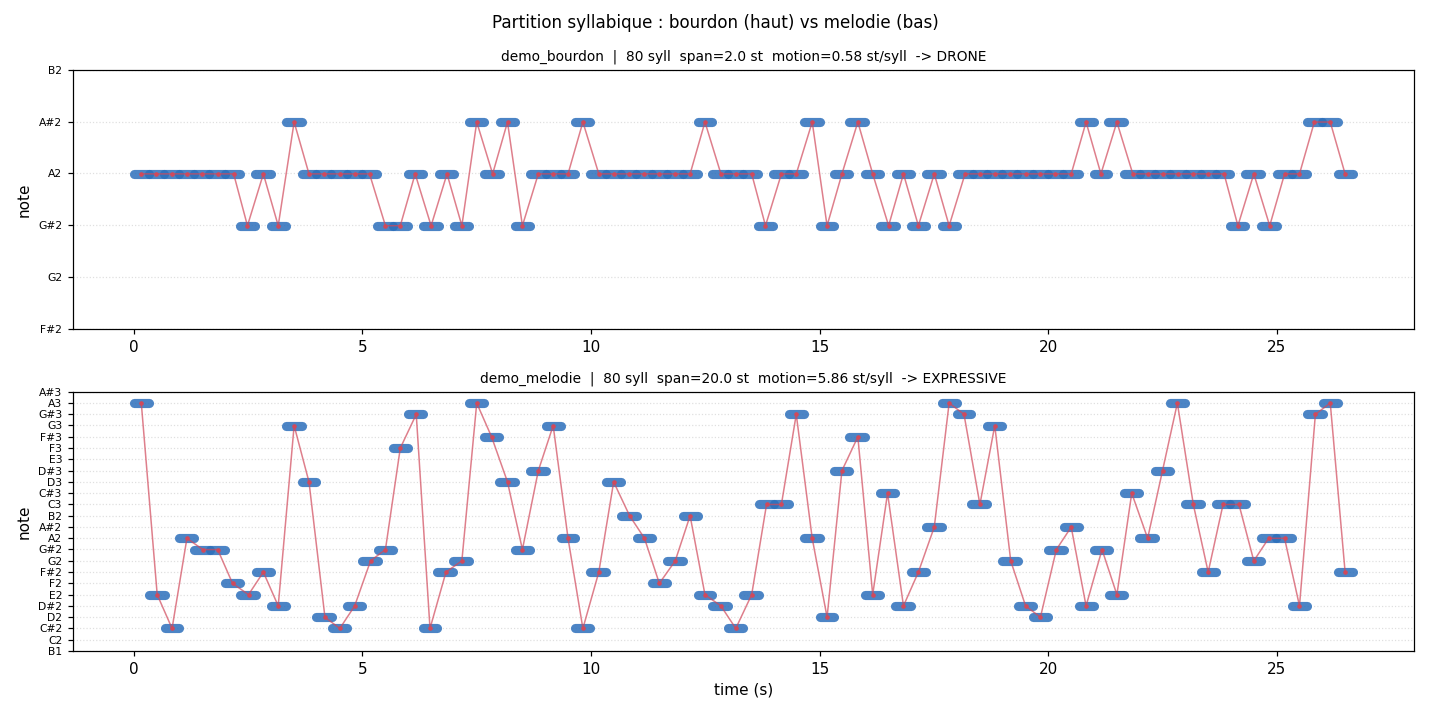

In [21]:
# La partition visible : piano-roll des deux clips empiles.
# Chaque barre horizontale = une syllabe a sa hauteur ; la ligne relie les centres.
png = SCORES_DIR / "partition_bourdon_vs_melodie.png"
sp.plot_score(
    [analyses["demo_bourdon"], analyses["demo_melodie"]],
    str(png),
    title="Partition syllabique : bourdon (haut) vs melodie (bas)",
)

from IPython.display import Image, display

print("partition ecrite :", png.name)
display(Image(filename=str(png)))


### 10.2 Deux axes de verdict : pourquoi l'axe local ne suffit pas

Les metriques **locales** -- `mean_abs_interval_st` (pas moyen entre syllabes
consecutives, en demi-tons) et `pct_flat_transitions` (fraction des transitions
de moins d'un demi-ton) -- sont mesurables sur n'importe quel clip, même très
court. Ce sont aussi les plus trompeuses seules : un bourdon qui **alterne deux
notes voisines** a des pas parfaitement sains et glisse sous le radar local.
La docstring de l'instrument garde la trace du cas reel qui a motive l'axe
structurel : l'extrait v4 de 2 min 30 a manque le verdict FLAT de 0,21
demi-ton sur le motion -- mais passait 72,8 % de ses 401 syllabes sur trois
demi-tons adjacents, avec 82,2 % de la sequence dans des motifs repetes.

Les metriques **structurelles** regardent la forme de la melodie elle-même :

- `effective_notes` : 2 eleve a l'entropie de la distribution des notes -- le
  nombre de notes que le clip utilise *vraiment* (la reference kokoro
  expressive mesure 11,8 ; l'extrait v4 drone 6,0) ;
- `top3_note_pct` : fraction des syllabes sur les 3 notes les plus frequentes ;
- `motif3_repeat_pct` : fraction des positions couvertes par un motif de 3
  notes qui apparait au moins deux fois.

Le verdict final combine les deux axes : `DRONE` si un critere structurel tire
(notes effectives < 7, top-3 >= 65 %, ou motifs repetes >= 60 %), sinon la
lecture locale (`FLAT` / `MODERATE` / `EXPRESSIVE`). La cellule suivante
confronte les deux lectures **sur les mesures ci-dessus** : la colonne
« local seul » est ce qu'un detecteur sans axe structurel conclurait ; la
colonne « complet » est ce que l'instrument reel conclut.


In [22]:
# Confrontation des deux axes SUR NOS MESURES.
# « local seul »   : classify_melody sans axes structurels (simulate un detecteur local-only).
# « complet »      : l'instrument reel, axes local + structure.
lignes = []
for nom in ("demo_bourdon", "demo_melodie"):
    a = analyses[nom]
    loc = sp.classify_melody(a["mean_abs_interval_st"], a["pct_flat_transitions"])
    complet = sp.classify_melody(
        a["mean_abs_interval_st"], a["pct_flat_transitions"],
        a["effective_notes"], a["top3_note_pct"], a["motif3_repeat_pct"],
    )
    lignes.append((nom, loc["local_verdict"], complet["verdict"], a))

entete = "%-14s %-11s %-9s  %6s %7s  %5s %6s %7s" % (
    "clip", "local seul", "complet", "motion", "flat%", "effn", "top3%", "motif3%")
print(entete)
print("-" * len(entete))
for nom, lv, fv, a in lignes:
    print("%-14s %-11s %-9s  %6.2f %6.1f%%  %5.1f %5.1f%% %6.1f%%" % (
        nom, lv, fv, a["mean_abs_interval_st"], a["pct_flat_transitions"],
        a["effective_notes"], a["top3_note_pct"], a["motif3_repeat_pct"]))


clip           local seul  complet    motion   flat%   effn  top3% motif3%
--------------------------------------------------------------------------
demo_bourdon   FLAT        DRONE        0.58   46.8%    2.3 100.0%   92.3%
demo_melodie   EXPRESSIVE  EXPRESSIVE    5.86    5.1%   17.8  25.0%    0.0%


La colonne decisice est la deuxieme : sur le bourdon, la lecture locale
s'arrete a `FLAT` (chant plat) tandis que le verdict complet dit `DRONE` -- avec
les trois raisons structurelles affichees : 2,3 notes effectives sur 80
syllabes, 100 % d'entre elles sur les trois mêmes notes, 92 % de la sequence
dans des motifs repetes. La classe locale dit « ça ne bouge pas » ; la classe
structurelle dit « c'est un bourdon » -- et c'est la seconde qu'un pipeline
de contrôle doit voir. Le pire cas n'est d'ailleurs pas celui-ci : sur
d'autres tirages, et sur le cas reel v4 documente dans l'instrument (rate de
0,21 demi-ton sur le motion), le local glisse a `MODERATE` -- un feu vert --
alors que la structure condamne. C'est exactement la quatrieme ligne du
tableau suivant : pas locaux sains, verdict `DRONE`.

Sur la melodie, les deux axes sont d'accord : 17,8 notes effectives,
concentration top-3 de 25 %, aucun motif repete. Un detecteur local-only
donnerait le même verdict par chance sur ce cas-ci ; l'axe structurel est ce
qui le rend fiable sur le cas qui compte -- le bourdon degenere qui imite une
lecture saine.

La cellule suivante interroge la politique de verdict **sans audio**
(`classify_melody` est une fonction pure) pour montrer son asymetrie
deliberee et la différence entre « non evalue » et « evalue, rien trouve ».


In [23]:
# La politique de verdict est pure et deterministe : interrogee sans audio.
# Asymetrie voulue : FLAT (classe de rejet) survit a une structure non evaluee ;
# MODERATE/EXPRESSIVE (feux verts) se degradent en INSUFFICIENT -- un feu vert
# qui a saute le detecteur de bourdon n'est pas un feu vert.
cas = [
    ("chant plat, clip court", (0.4, 75.0, None, None, None)),
    ("lecture variee, clip court", (2.8, 20.0, None, None, None)),
    ("lecture variee, clip long evalue propre", (2.8, 20.0, 9.5, 30.0, 20.0)),
    ("bourdon masque : pas locaux sains", (1.3, 35.0, 5.0, 78.0, 85.0)),
]
print("%-38s %-12s %-11s %-12s %s" % (
    "cas", "verdict", "local", "structure", "drone_reasons"))
print("-" * 108)
for label, args in cas:
    v = sp.classify_melody(*args)
    dr = v["drone_reasons"]
    if dr is None:
        dr_s = "None (non evalue)"
    elif not dr:
        dr_s = "[] (evalue, rien trouve)"
    else:
        dr_s = " ; ".join(dr)
    print("%-38s %-12s %-11s %-12s %s" % (
        label, v["verdict"], v["local_verdict"],
        "evaluee" if v["structure_assessed"] else "non evaluee", dr_s))


cas                                    verdict      local       structure    drone_reasons
------------------------------------------------------------------------------------------------------------
chant plat, clip court                 FLAT         FLAT        non evaluee  None (non evalue)
lecture variee, clip court             INSUFFICIENT EXPRESSIVE  non evaluee  None (non evalue)
lecture variee, clip long evalue propre EXPRESSIVE   EXPRESSIVE  evaluee      [] (evalue, rien trouve)
bourdon masque : pas locaux sains      DRONE        MODERATE    evaluee      effective_notes 5.0 < 7.0 ; top3_note_pct 78.0% >= 65.0% ; motif3_repeat_pct 85.0% >= 60.0%


### 10.3 Le seuil de 60 syllabes : savoir s'abstenir

Les trois statistiques de concentration sont des proportions : sur un
echantillon court, elles ne veulent plus rien dire. Tirer 3 notes sur 24
syllabes peut donner 40 % de top-3 par pur hasard ; sur 80 syllabes, une telle
concentration signale un vrai effondrement melodique. L'instrument fixe donc
`MIN_SYLL_FOR_STRUCTURE = 60` : en dessous, `melody_stats` refuse de retourner
des zeros silencieux (qui se liraient « propre ») et rend explicitement les
clés structurelles a `None`, avec la raison dans `structure_na_reason`.

La consequence sur le verdict est une **asymetrie deliberee** : un `FLAT`
(mesure sur l'axe local seul) survit a une structure non evaluee -- c'est une
classe de rejet, et s'abstenir l'affaiblirait sur les clips qu'il doit
attraper. En revanche `MODERATE` et `EXPRESSIVE` sont des feux verts : un feu
vert qui a saute le detecteur de bourdon n'en est pas un. Ils se degradent en
`INSUFFICIENT`, que le pipeline amont traduit par une abstention plutot qu'un
passage. La distinction `None` (non evalue) vs `[]` (evalue, rien trouve)
existe pour la même raison : *pas regarde* et *rien trouve* ne doivent pas se
ressembler sur un rapport d'audit.

La demonstration : la même melodie variee, coupee a 24 syllabes -- la lecture
locale reste saine, mais elle n'est plus certifiable.


In [24]:
# Le seuil d'abstention en pratique : meme melodie variee, coupee a 24 syllabes.
random.seed(42)
seq_courte = [45 + random.choice(range(-8, 13)) for _ in range(24)]
y, sr = sp._synth(seq_courte, syll_per_s=3.0)
wav_court = SCORES_DIR / "demo_melodie_courte.wav"
sf.write(wav_court, y, sr)

a_court = sp.analyze_syllables(str(wav_court))
sp.print_score_table(a_court)



=== demo_melodie_courte  (8.0s, 24 syllables, module=8ada88f505da) ===
  melody: A3 E2 C#2 A2 G#2 G#2 F2 E2 F#2 D#2 G3 D3 D2 C#2 D#2 G2 G#2 F3 G#3 C#2 F#2 G2 A3 F#3
  span=20.0 st (p5-p95 19.85 st) | motion=5.78 st/syll | flat-transitions=4.3% | rate=3.0/s | median=98.0 Hz
  structure: n/a (only 24 syllables, need >= 60)
  VERDICT  : INSUFFICIENT
             (criteres de bourdon NON evalues -> lecture locale 'EXPRESSIVE' non certifiee)


### Exemple guidé : piéger l'axe local (groupe G17, PR #23242)

**Duree estimee :** 15-20 minutes

**Objectif** : construire une sequence de 80 syllabes dont le verdict local
n'est PAS `FLAT` (pas moyens sains, peu de transitions plates) mais dont le
verdict complet est `DRONE` -- le leurre symetrique du bourdon de la
demonstration, ou la structure repetee est cachee derriere des pas locaux
sains.

**Contexte** : le bourdon de la section 10.1 est un cas facile pour l'axe
local (trois quarts des syllabes sur la même note). Le vrai piege -- celui qui
a motive l'axe structurel -- est une sequence qui *bouge* localement mais
*repete* : un motif de 3 notes avec des pas de 2 a 4 demi-tons, assez grands
pour passer `MOTION_FLAT_MAX` et rester sous `FLATPCT_FLAT_MIN`, repete
presque tel quel jusqu'a 80 syllabes.

- **Étape 1 :** définir un motif de 3 notes (autour de A2) dont les pas
  consecutifs font au moins 1.5 demi-ton chacun
- **Étape 2 :** construire la sequence en repetant le motif jusqu'a 80
  syllabes (une legere variation d'ordre des notes garde le caractère repetitif)
- **Étape 3 :** synthetiser, analyser, et verifier les trois critères
  structurels attendus : `effective_notes` bas, `top3_note_pct` très haut,
  `motif3_repeat_pct` proche de 100 %

**Indice :** `effective_notes` est pilote par l'entropie -- avec seulement 3
notes presentes, il plafonne a 3.0 quelle que soit leur ordre
**Indice :** avec un motif fixe de 3 notes, `motif3_repeat_pct` couvre toutes
les positions -- visez la sequence la plus periodique possible


Séquence construite : 80 syllabes, pas min 3 st, pas moyen 4.65 st



=== demo_leurre_local  (26.67s, 80 syllables, module=8ada88f505da) ===
  melody: A2 C3 E3 A2 E3 C3 A2 C3 E3 A2 E3 C3 A2 C3 E3 A2 C3 E3 A2 E3 C3 A2 C3 E3 A2 E3 C3 A2 C3 E3 A2 E3 C3 A2 E3 C3 A2 C3 E3 A2 C3 E3 A2 E3 C3 A2 E3 C3 A2 C3 E3 A2 C3 E3 A2 C3 E3 A2 C3 E3 A2 C3 E3 A2 E3 C3 A2 C3 E3 A2 C3 E3 A2 E3 C3 A2 E3 C3 A2 C3
  span=7.0 st (p5-p95 7.0 st) | motion=4.65 st/syll | flat-transitions=0.0% | rate=3.0/s | median=130.8 Hz
  structure: 3.0 notes effectives sur 3 distinctes | top-3 ['A2', 'C3', 'E3'] = 100.0% | motifs 3-notes repetes 100.0%
  motifs   : A2-C3-E3 x15 | C3-E3-A2 x15 | A2-E3-C3 x11
  VERDICT  : DRONE
             drone: effective_notes 3.0 < 7.0
             drone: top3_note_pct 100.0% >= 65.0%
             drone: motif3_repeat_pct 100.0% >= 60.0%

local seul : EXPRESSIVE | complet : DRONE
Les trois critères structurels se déclenchent : le leurre est attrapé par l'axe structurel.
Transcription : 80/80 syllabes sur la note écrite

Robustesse sur 5 graines (variation d'ord

  graine 0 : local EXPRESSIVE complet DRONE   motion 4.65 st, effn 3.0, top3 100 %, motif3 95 %


  graine 1 : local EXPRESSIVE complet DRONE   motion 4.70 st, effn 3.0, top3 100 %, motif3 100 %


  graine 2 : local EXPRESSIVE complet DRONE   motion 4.65 st, effn 3.0, top3 100 %, motif3 100 %


  graine 3 : local EXPRESSIVE complet DRONE   motion 4.65 st, effn 3.0, top3 100 %, motif3 99 %


  graine 4 : local EXPRESSIVE complet DRONE   motion 4.65 st, effn 3.0, top3 100 %, motif3 100 %


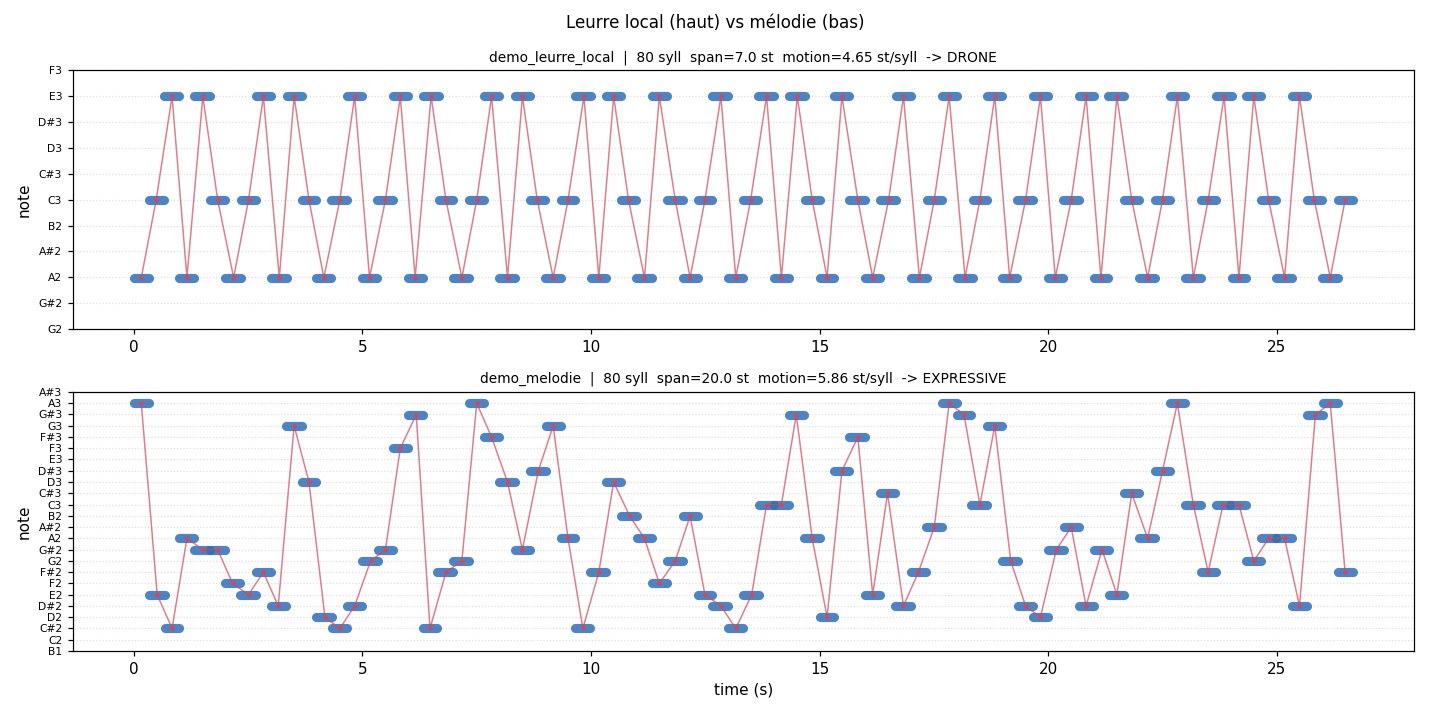

In [25]:
    # Exemple guidé — résolution du groupe G17 (Killian Barret), PR #23242, revue et intégrée.
# Exercice : construire un leurre pour l'axe local
# Étape 1 : motif de 3 notes autour de A2 (MIDI 45) : A2 -> C3 -> E3, soit +3, +4 puis -7 au retour.
# Chaque pas fait au moins 1,5 demi-ton : le pas moyen dépasse MOTION_FLAT_MAX et aucune
# transition n'est plate, donc l'axe local ne peut pas conclure FLAT.
MOTIF_LEURRE = [45, 48, 52]

# Étape 2 : répéter le motif jusqu'à 80 syllabes, avec une légère variation d'ordre
def leurre_local(n_syll=80, seed=7):
    """Séquence périodique : le motif A2-C3-E3 répété, et un cycle sur quatre environ joué
    A2-E3-C3 (variation d'ordre). Tous les pas, jonctions comprises, font au moins 3 demi-tons."""
    rng = random.Random(seed)
    sequence = []
    while len(sequence) < n_syll:
        cycle = list(MOTIF_LEURRE)
        if rng.random() < 0.25:
            cycle[1], cycle[2] = cycle[2], cycle[1]
        sequence.extend(cycle)
    return sequence[:n_syll]

leurre_seq = leurre_local()
pas = [abs(b - a) for a, b in zip(leurre_seq, leurre_seq[1:])]
assert min(pas) >= 1.5, "un pas est trop petit"
print(f"Séquence construite : {len(leurre_seq)} syllabes, pas min {min(pas)} st, "
      f"pas moyen {sum(pas) / len(pas):.2f} st")

# Étape 3 : synthétiser, analyser, vérifier
y, sr = sp._synth(leurre_seq, syll_per_s=3.0)
wav_leurre = SCORES_DIR / "demo_leurre_local.wav"
sf.write(wav_leurre, y, sr)
a_leurre = sp.analyze_syllables(str(wav_leurre))
sp.print_score_table(a_leurre)

v_local = sp.classify_melody(a_leurre["mean_abs_interval_st"], a_leurre["pct_flat_transitions"])
v_complet = sp.classify_melody(a_leurre["mean_abs_interval_st"], a_leurre["pct_flat_transitions"],
                               a_leurre["effective_notes"], a_leurre["top3_note_pct"],
                               a_leurre["motif3_repeat_pct"])
print(f"\nlocal seul : {v_local['local_verdict']} | complet : {v_complet['verdict']}")
assert v_local["local_verdict"] != "FLAT", "le leurre doit passer l'axe local"
assert v_complet["verdict"] == "DRONE", "la structure doit le condamner"
assert a_leurre["effective_notes"] < sp.EFFNOTES_DRONE_MAX
assert a_leurre["top3_note_pct"] >= sp.TOP3_DRONE_MIN
assert a_leurre["motif3_repeat_pct"] >= sp.MOTIF3_DRONE_MIN
print("Les trois critères structurels se déclenchent : le leurre est attrapé par l'axe structurel.")

# Contrôle : l'instrument a-t-il bien transcrit les notes écrites ? (vérité terrain connue)
notes_mesurees = [s["note"] for s in a_leurre["syllables"]]
attendues = [sp.midi_to_note_name(m) for m in leurre_seq]
if len(notes_mesurees) == len(attendues):
    justes = sum(m == e for m, e in zip(notes_mesurees, attendues))
    print(f"Transcription : {justes}/{len(attendues)} syllabes sur la note écrite")
else:
    print(f"Transcription : {len(notes_mesurees)} syllabes détectées pour {len(attendues)} écrites")

# Robustesse : le résultat ne doit pas dépendre d'un tirage chanceux
print("\nRobustesse sur 5 graines (variation d'ordre différente) :")
for graine in range(5):
    seq = leurre_local(seed=graine)
    y, sr = sp._synth(seq, syll_per_s=3.0)
    chemin = SCORES_DIR / f"demo_leurre_graine{graine}.wav"
    sf.write(chemin, y, sr)
    a = sp.analyze_syllables(str(chemin))
    v = sp.classify_melody(a["mean_abs_interval_st"], a["pct_flat_transitions"],
                           a["effective_notes"], a["top3_note_pct"], a["motif3_repeat_pct"])
    print(f"  graine {graine} : local {v['local_verdict']:10} complet {v['verdict']:7} "
          f"motion {a['mean_abs_interval_st']:.2f} st, effn {a['effective_notes']:.1f}, "
          f"top3 {a['top3_note_pct']:.0f} %, motif3 {a['motif3_repeat_pct']:.0f} %")
    chemin.unlink()

png_leurre = SCORES_DIR / "partition_leurre_vs_melodie.png"
sp.plot_score([a_leurre, analyses["demo_melodie"]], str(png_leurre),
              title="Leurre local (haut) vs mélodie (bas)")
display(Image(filename=str(png_leurre)))


### Analyse de l'exemple guidé : le leurre de l'axe local

**Construction.** Le motif A2 → C3 → E3 (pas de +3 et +4 demi-tons, retour de −7) est répété jusqu'à 80 syllabes, et environ un cycle sur quatre est joué dans l'ordre A2 → E3 → C3. Tous les pas, jonctions comprises, font au moins 3 demi-tons : le pas moyen vaut 4,65 demi-tons par syllabe, loin au-dessus du seuil `MOTION_FLAT_MAX` (1), et aucune transition n'est plate.

**Résultat.** L'instrument retrouve les 80 notes écrites. L'axe local conclut `EXPRESSIVE` : vue de près, la séquence bouge beaucoup. L'axe structurel la condamne sur ses trois critères :
- 3,0 notes effectives (seuil : 7) ;
- 100 % des syllabes sur les 3 notes les plus fréquentes (seuil : 65 %) ;
- 100 % de la séquence couverte par des motifs de 3 notes répétés (seuil : 60 %).

Le verdict complet est `DRONE`, et les assertions de la cellule le vérifient. Le contrôle sur cinq graines donne le même verdict à chaque fois (motifs répétés entre 95 et 100 %) : le résultat ne dépend pas d'une variation d'ordre chanceuse.

**Pourquoi c'est le cas qui compte.** C'est le défaut typique d'une voix de synthèse qui « chante » : une intonation qui monte et descend à chaque groupe de mots, mais toujours selon le même dessin. À l'oreille, la monotonie se perçoit au bout de quelques phrases, alors que les mesures locales la jugent saine. Seul un regard sur la forme globale de la mélodie (quelles notes, quels motifs, à quelle fréquence) l'attrape.

**Limites.** Comme pour les autres démonstrations de la section, le signal est synthétique : des syllabes propres, sur des notes exactes, plus faciles à transcrire qu'une voix réelle. Les seuils servent à séparer des classes de clips, pas à juger finement un clip isolé.


### Exercice : mesurer la robustesse de l'instrument au bruit

**Durée estimée :** 15-20 minutes

**Objectif** : construire `ajouter_bruit(y, snr_db, seed)` et mesurer à partir de quel rapport signal/bruit les trois critères structurels cessent de condamner un bourdon.

**Contexte** : toutes les mesures de la section 10 sont faites sur des signaux synthétiques propres. Un extrait réel n'est jamais propre : la question n'est pas « l'instrument marche-t-il ? » mais « jusqu'où tient-il ? ». C'est la différence entre une démonstration et un instrument.

- **Étape 1 :** ajouter un bruit blanc gaussien au signal, calibré sur une puissance de signal mesurée (et non sur une amplitude choisie à l'œil)
- **Étape 2 :** analyser le même bourdon à plusieurs rapports signal/bruit décroissants
- **Étape 3 :** relever le rapport auquel le verdict cesse d'être `DRONE`, et dire ce que cela implique pour un clip réel

**Indice :** `snr_db = 10 * log10(P_signal / P_bruit)` ; déduis l'écart-type du bruit de la puissance mesurée du signal.
**Indice :** fixe la graine (`numpy.random.default_rng(seed)`) : sans elle, la conclusion dépend d'un tirage.

In [26]:
# Exercice a completer : robustesse de l'instrument au bruit
import numpy as np

def ajouter_bruit(y, snr_db, seed=0):
    """Ajoute un bruit blanc gaussien au signal `y` pour un rapport signal/bruit donne (en dB)."""
    # TODO etudiant
    return y  # TODO etudiant

# Etape 2 : analyser le bourdon a plusieurs rapports signal/bruit decroissants
# TODO etudiant : boucler sur les rapports, ecrire le wav, appeler sp.analyze_syllables

# Etape 3 : relever le rapport auquel le verdict cesse d'etre DRONE
print("Exercice a completer")

Exercice a completer


### 10.4 Limites honnetes de la demonstration

Deux precautions avant de conclure. D'abord, la **variance d'exécution** : les
sequences de cette section sont tirees aleatoirement, et deux tirages
différents donnent des chiffres différents -- sur des mesures reelles de la
memoire v4, la même configuration a rendu 12,9 puis 9,7 notes effectives. Le
`random.seed` fixe rend *ce notebook* reproductible, mais une ligne de tableau
n'est pas une loi : les seuils de l'instrument sont calibres pour separer des
*classes* de clips, pas pour etalonner un clip individuel au dixieme de
demi-ton pres.

Ensuite, la **nature du signal** : le synthetiseur syllabique produit des
syllabes propres et periodiques -- plus faciles a transcrire qu'une voix TTS
reelle, ou le timbre, le jitter et les consonnes perturbent pyin et la
detection de noyaux. Sur un vrai clip, l'instrument s'invoque exactement de la
même maniere (`analyze_syllables` sur le chemin du clip) ; la partition et les
verdicts sont simplement plus bruites. C'est la demonstration qui est
synthetique, pas l'instrument : ses references de calibration (docstring de
`melody_stats`) ont ete mesurees sur des clips TTS reels.

Avec l'annotation (sections 1 a 9) et la mesure (cette section), le pipeline
dispose des deux moities du contrôle qualite : une intention declarative par
segment, et un instrument autonome pour verifier ce que la voix generee en
fait au passage P4.


## 11. Conclusion

### Livrables P3

| Fichier | Description | Lecteur |
|---------|-------------|---------|
| `prosodic_output/prosodic_annotations.json` | Contrat P3 → P4 (version 2.0) : voix (`character_id`), tags détectés, retenus et insérés, texte FishAudio S2 | P4 (04-11) |
| `prosodic_output/book.ssml.md` | Livre de relecture, produit par le même moteur, avec la liste des attributions à vérifier en P1 | Relecture humaine |
| `prosodic_output/test_integration/` | Extraits synthétisés du test P3/P4 (section 9 bis), avec la transcription qui les accompagne | Audit |
| `prosodic_output/scores_mesure/partition_bourdon_vs_melodie.png` | Partition syllabique bourdon vs mélodie (section 10, instrument #1877) | Audit |

### Moteur exporté

Le moteur exporté est le **moteur retenu (v2)** de la section 6 bis. Il repose sur :
- des mots-clés normalisés (accents) et ancrés en début de mot ;
- la phrase qui introduit chaque réplique, qui sert à la fois à détecter l'émotion et à vérifier ou corriger le locuteur ;
- des priorités et des conflits explicites, avec un plafond de 3 tags ;
- un placement des tags là où le changement a lieu.

Chaque tag retenu est inséré exactement une fois, et les statistiques sont calculées sur les tags réellement insérés. Le moteur d'origine (v1) reste affiché pour comparaison, avec un ordre de tags désormais stable.

### Passage à P4

**Statut : contrat préparé côté P3, incompatibilités identifiées, synthèse testée sur un échantillon (modèle gratuit).** `book.ssml.md` n'est pas le fichier de génération : P4 lit `prosodic_annotations.json`. Le test de la section 9 bis, exécuté sur le code réel de 04-11, établit trois corrections à faire en aval :
- P4 doit lire `character_id` : sinon la Comtesse reçoit la voix du comte, et deux personnages retombent sur le narrateur ;
- P4 doit envoyer `fishaudio_text` : sa conversion produit la syntaxe de l'ancien modèle S1 — audible (aucun tag n'est prononcé à voix haute, vérifié par transcription), mais pas fidèle aux tags officiels S2 ;
- P2 doit fournir des références de voix FishAudio (`reference_id`) : sans elles, tous les personnages ont la même voix par défaut.

La synthèse a été exécutée avec le modèle **gratuit** `fish-audio/s2.1-pro-free:free` via OpenRouter (clé lue dans un `.env` non versionné) ; le modèle payant n'est proposé que si `FISHAUDIO_ALLOW_PAID=1`.

### Limites de cette approche

- L'annotation reste fondée sur des mots-clés et sur la ponctuation, pas sur une compréhension du texte : un rire « muet » devient un rire audible, et l'émotion d'un interlocuteur peut être attribuée à celui qui parle.
- 19 répliques sur 39 restent sans locuteur résolu : les résoudre demande de suivre les pronoms d'une phrase à l'autre, ce qui relève de P1.
- `[quick]` n'a pas d'équivalent parmi les tags officiels de FishAudio S2 et est supprimé à la conversion. `[slow]` est rendu par `[pause]` : c'est une approximation, car ralentir une lecture et marquer une pause sont deux intentions différentes ; quand `slow` accompagne un `pause`, les deux fusionnent et le ralentissement disparaît (11 segments).
- Plusieurs tags restent imposés par des règles plutôt que par le texte : le ton par défaut des rôles (`cold` pour l'officier, `warm` pour Boule de Suif) et la pause par défaut de la narration.
- La section 10 mesure la mélodie sur des signaux synthétiques : elle ne mesure pas encore l'effet des annotations sur une voix TTS réelle.
- La validation par synthèse porte sur 6 extraits (3 segments × 2 syntaxes) au modèle gratuit, sans référence de voix : elle prouve que les balises ne sont pas prononcées, pas que chaque personnage est distingué.
- Les mesures de la section 10 dépendent de la version de librosa : la 0.11.0 reproduit exactement les valeurs commentées, la 1.0.0 donne 17,4 notes effectives au lieu de 17,8 pour la mélodie (verdicts inchangés).

> *Repère de production —* Epic #1028, troisième passe du pipeline audiobook : annotation prosodique.